# **SPARK ON YARN + HDFS - TIPE 1: PRAPEMROSESAN TERDISTRIBUSI & PELATIHAN TERPUSAT GPU**
## **Pipeline ConvNeXt-Tiny (Baseline) · Skenario Irisan 3 Kelas (Nevus, Melanoma, Seborrheic Keratosis)**

Notebook ini memindahkan pipeline baseline `00_baseline_convnext_tiny_ak84` (HAM10000 + ISIC 2019, ROI crop berbasis mask, ConvNeXt-Tiny PyTorch/timm) ke arsitektur hybrid **Spark on YARN + HDFS** (kerangka `sk1-irisan-tipe1-ringkas-optimasi`):

1. **PySpark on YARN + HDFS:** citra asli dan mask diunggah ke HDFS, lalu prapemrosesan (hair removal → ROI crop → CLAHE → pad & resize 224) dijalankan paralel di executor. Hasilnya ditulis sebagai shard `.npz` ke HDFS.
2. **Pelatihan terpusat di satu GPU (driver):** shard dikumpulkan ke array NumPy di driver, Spark dihentikan, lalu ConvNeXt-Tiny dilatih dengan resep baseline. **Spark hanya mengerjakan bagian data; model tidak dilatih terdistribusi.**

**Skenario eksperimen:** `12 executor - 8 partisi` dan `8 executor - 12 partisi`. Ubah `NUM_WORKERS`, `NUM_PARTITIONS`, dan `REPLICATE` pada Fase 1, lalu jalankan ulang notebook (disarankan *Restart runtime* di antara dua run agar pengukuran waktu dan RAM adil).

### Apa yang dipertahankan dari baseline (agar perbandingan adil)
| Komponen | Status |
|---|---|
| Manifest split resmi (train/val/test), sumber dataset KaggleHub, pasangan citra-mask | identik (sel dimuat apa adanya) |
| Urutan preprocessing: hair removal → ROI crop (pad 15%) → CLAHE → pad reflect & resize 224 (INTER_AREA) | identik; citra asli (tanpa resize awal) dibaca dari HDFS |
| Simpan-baca JPEG (kualitas default 95) yang di baseline terjadi lewat `imwrite`/`imread` | direplikasi di executor lewat `imencode`/`imdecode` |
| Urutan sampel di array train/val/test | identik dengan urutan manifest (dirakit berdasarkan `image_id`) |
| ConvNeXt-Tiny, 2 fase (4 + maks 15 epoch), AdamW, cosine LR, class weight, augmentasi warna + `ColorTemp`, seed 42, seleksi model berdasar Val Macro-F1, test dievaluasi sekali | identik (sel training/evaluasi baseline dipakai apa adanya) |

### Apa yang diganti
Pembacaan data (`ThreadPoolExecutor` lokal) → Spark on YARN + HDFS; checkpoint diberi nama per skenario; ditambah pencatatan `results.csv` (waktu alokasi YARN, preprocessing, tulis shard, kumpul ke driver, training).

## Fase 0: Inisialisasi Log Eksperimen

> **Catatan:** Jalankan sel penghapusan di bawah hanya jika ingin mereset hasil log dari awal. Jika ingin mengakumulasi hasil run (skenario dan replikasi) ke dalam `results.csv`, lewati sel di bawah.

In [1]:
# !rm -f /content/drive/MyDrive/riset_kanker_kulit/results.csv

## Fase 1 - Setup Lingkungan, Parameter Eksperimen, dan Direktori Kerja
Environment: **Google Colab (GPU A100, 12 vCPU)**, sama dengan baseline ConvNeXt. Sel ini mendefinisikan parameter skenario, menginstal Java 11 + SSH + Hadoop 3.3.6 + Spark 3.5.5, dan memverifikasi instalasi.

In [2]:
from pathlib import Path
import os
import sys

# Environment: Google Colab (A100 40GB + 12 vCPU), sama dengan baseline ConvNeXt-Tiny.
if not Path("/content").exists() or Path("/kaggle/working").exists():
    raise RuntimeError("Notebook ini dirancang untuk Google Colab (GPU A100, 12 vCPU).")

ENV_NAME = "colab"
INSTALL_DIR = Path("/content")
PROJECT_DIR = Path("/content/drive/MyDrive/riset_kanker_kulit")
print("Terdeteksi lingkungan: Google Colab")
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Peringatan saat mount drive:", e)

PROJECT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Direktori kerja utama: {PROJECT_DIR}")

# ------------------------------------------------------------------
# Konfigurasi skenario eksperimen
# Dua skenario terencana: (NUM_WORKERS, NUM_PARTITIONS) = (12, 8) dan (8, 12)
# REPLICATE: nomor ulangan run untuk skenario yang sama (1, 2, 3, ...)
# ------------------------------------------------------------------
NUM_WORKERS = 12
NUM_PARTITIONS = 12
REPLICATE = 2
SCENARIO_TYPE = "irisan"

SCENARIO_NAME = f"{SCENARIO_TYPE}_{NUM_WORKERS}W{NUM_PARTITIONS}P"

# Versi komponen sistem
HADOOP_VERSION = "3.3.6"
SPARK_VERSION = "3.5.5"
SPARK_HADOOP_PROFILE = "hadoop3"

SSH_PORT = 2222

# Path instalasi lokal (ephemeral per sesi)
HADOOP_HOME = INSTALL_DIR / "hadoop"
SPARK_HOME = INSTALL_DIR / "spark"
HADOOP_CONF_DIR = HADOOP_HOME / "etc" / "hadoop"

DATA_DIR = INSTALL_DIR / "hadoop_data"
NAMENODE_DIR = DATA_DIR / "namenode"
DATANODE_DIR = DATA_DIR / "datanode"

# Struktur HDFS: citra asli, mask, dan shard hasil preprocessing dipisah
HDFS_WORKDIR = f"/user/skincancer/{SCENARIO_TYPE}"
HDFS_IMG_DIR = f"{HDFS_WORKDIR}/images"
HDFS_MASK_DIR = f"{HDFS_WORKDIR}/masks"
HDFS_SHARD_DIR = f"{HDFS_WORKDIR}_shards"   # sengaja di luar HDFS_WORKDIR

# Direktori cache dan script
CACHE_DIR = PROJECT_DIR / "cache"
SCRIPT_DIR = PROJECT_DIR / "scripts"
SETUP_SCRIPT_PATH = SCRIPT_DIR / "setup_env.sh"

CACHE_DIR.mkdir(parents=True, exist_ok=True)
SCRIPT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Skenario: {SCENARIO_NAME} | Replikasi: {REPLICATE}")
print(f"Hadoop Home: {HADOOP_HOME}")
print(f"Spark Home: {SPARK_HOME}")
print(f"HDFS Workdir: {HDFS_WORKDIR}")

Terdeteksi lingkungan: Google Colab
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Direktori kerja utama: /content/drive/MyDrive/riset_kanker_kulit
Skenario: irisan_12W12P | Replikasi: 2
Hadoop Home: /content/hadoop
Spark Home: /content/spark
HDFS Workdir: /user/skincancer/irisan


In [3]:
# ------------------------------------------------------------------
# Pencatatan hasil eksperimen (results.csv di Google Drive)
# 13 kolom pertama sama dengan notebook sk1; 2 kolom tambahan di akhir
# (replicate, val_macro_f1) untuk analisis replikasi/ANOVA dan seleksi model.
# ------------------------------------------------------------------
import csv
import time

RESULTS_LOG_PATH = PROJECT_DIR / "results.csv"
LOG_COLUMNS = [
    "timestamp", "scenario", "num_workers", "num_partitions", "stage",
    "elapsed_sec", "image_count", "avg_cpu_percent", "avg_mem_mb",
    "accuracy", "f1_score", "loss", "roc_auc",
    "replicate", "val_macro_f1",
]


def ensure_log_header():
    # Validasi skema results.csv sebelum menulis. File dari versi notebook lama
    # (jumlah kolom berbeda) diarsipkan agar baris baru tidak menempel di bawah header yang salah.
    if RESULTS_LOG_PATH.exists():
        with open(RESULTS_LOG_PATH, newline="") as f:
            header = next(csv.reader(f), [])
        if header != LOG_COLUMNS:
            backup = RESULTS_LOG_PATH.with_name(
                f"results_legacy_{time.strftime('%Y%m%d_%H%M%S')}.csv"
            )
            RESULTS_LOG_PATH.rename(backup)
            print(f"Skema lama terdeteksi ({len(header)} kolom). File diarsipkan ke: {backup.name}")

    if not RESULTS_LOG_PATH.exists():
        with open(RESULTS_LOG_PATH, "w", newline="") as f:
            csv.writer(f).writerow(LOG_COLUMNS)
        print(f"File log baru dibuat dengan {len(LOG_COLUMNS)} kolom.")


def log_result(stage, elapsed_sec, image_count=None, avg_cpu=None, avg_mem=None,
               accuracy=None, f1=None, loss=None, roc_auc=None, val_f1=None):
    ensure_log_header()

    def _f(v, nd=4):
        return f"{v:.{nd}f}" if v is not None else ""

    with open(RESULTS_LOG_PATH, "a", newline="") as f:
        csv.writer(f).writerow([
            time.strftime("%Y-%m-%d %H:%M:%S"),
            SCENARIO_NAME, NUM_WORKERS, NUM_PARTITIONS,
            stage, f"{elapsed_sec:.2f}",
            image_count if image_count is not None else "",
            _f(avg_cpu, 2), _f(avg_mem, 2),
            _f(accuracy), _f(f1), _f(loss), _f(roc_auc),
            REPLICATE, _f(val_f1),
        ])
    print(f"[LOG] {stage} ({SCENARIO_NAME}, replikasi {REPLICATE}) -> {RESULTS_LOG_PATH.name}")

In [4]:
SETUP_SCRIPT = f"""#!/bin/bash
set -e

HADOOP_VERSION="{HADOOP_VERSION}"
SPARK_VERSION="{SPARK_VERSION}"
SPARK_HADOOP_PROFILE="{SPARK_HADOOP_PROFILE}"
SSH_PORT="{SSH_PORT}"

INSTALL_DIR="{INSTALL_DIR}"
HADOOP_HOME="{HADOOP_HOME}"
SPARK_HOME="{SPARK_HOME}"
CACHE_DIR="{CACHE_DIR}"

HADOOP_ARCHIVE="hadoop-${{HADOOP_VERSION}}.tar.gz"
SPARK_ARCHIVE="spark-${{SPARK_VERSION}}-bin-${{SPARK_HADOOP_PROFILE}}.tgz"

HADOOP_URL="https://archive.apache.org/dist/hadoop/common/hadoop-${{HADOOP_VERSION}}/${{HADOOP_ARCHIVE}}"
SPARK_URL="https://archive.apache.org/dist/spark/spark-${{SPARK_VERSION}}/${{SPARK_ARCHIVE}}"

mkdir -p "${{CACHE_DIR}}"

fetch_archive() {{
    local archive_name="$1"
    local url="$2"
    local local_path="${{INSTALL_DIR}}/${{archive_name}}"
    local cache_path="${{CACHE_DIR}}/${{archive_name}}"

    if [ -f "${{local_path}}" ]; then
        return 0
    fi

    if [ -f "${{cache_path}}" ]; then
        echo "Menggunakan cache arsip dari storage persisten: ${{archive_name}}"
        cp "${{cache_path}}" "${{local_path}}"
    else
        echo "Mengunduh ${{archive_name}}..."
        if command -v aria2c >/dev/null 2>&1; then
            aria2c -x 8 -s 8 -q -d "${{INSTALL_DIR}}" -o "${{archive_name}}" "${{url}}"
        else
            wget -q "${{url}}" -O "${{local_path}}"
        fi
        if [ -d "${{CACHE_DIR}}" ]; then
            cp "${{local_path}}" "${{cache_path}}" || true
        fi
    fi
}}

echo "=== 1. Memeriksa Java 11 ==="
dpkg -s openjdk-11-jdk-headless >/dev/null 2>&1 || {{
    apt-get update -qq
    apt-get install -y -qq openjdk-11-jdk-headless
}}

echo "=== 2. Memeriksa Hadoop ${{HADOOP_VERSION}} ==="
if [ ! -d "${{HADOOP_HOME}}" ]; then
    fetch_archive "${{HADOOP_ARCHIVE}}" "${{HADOOP_URL}}"
    tar -xzf "${{INSTALL_DIR}}/${{HADOOP_ARCHIVE}}" -C "${{INSTALL_DIR}}"
    mv "${{INSTALL_DIR}}/hadoop-${{HADOOP_VERSION}}" "${{HADOOP_HOME}}"
fi

echo "=== 3. Memeriksa Spark ${{SPARK_VERSION}} ==="
if [ ! -d "${{SPARK_HOME}}" ]; then
    fetch_archive "${{SPARK_ARCHIVE}}" "${{SPARK_URL}}"
    tar -xzf "${{INSTALL_DIR}}/${{SPARK_ARCHIVE}}" -C "${{INSTALL_DIR}}"
    mv "${{INSTALL_DIR}}/spark-${{SPARK_VERSION}}-bin-${{SPARK_HADOOP_PROFILE}}" "${{SPARK_HOME}}"
fi

echo "=== 4. Konfigurasi SSH Localhost ==="
dpkg -s openssh-server >/dev/null 2>&1 || {{
    apt-get update -qq
    apt-get install -y -qq openssh-server openssh-client
}}
mkdir -p /var/run/sshd ~/.ssh

ssh-keygen -A

[ -f ~/.ssh/id_rsa ] || ssh-keygen -t rsa -P '' -f ~/.ssh/id_rsa -q
touch ~/.ssh/authorized_keys
grep -qxF "$(cat ~/.ssh/id_rsa.pub)" ~/.ssh/authorized_keys || cat ~/.ssh/id_rsa.pub >> ~/.ssh/authorized_keys
chmod 700 ~/.ssh
chmod 600 ~/.ssh/authorized_keys

# Set port SSH secara idempoten: hapus semua direktif Port lama, lalu tulis satu baris baru.
# (Pendekatan sed berantai sebelumnya menghasilkan "Port 222222" karena "Port 2222"
#  masih cocok dengan pola "Port 22".)
sed -i -E '/^[[:space:]]*#?[[:space:]]*Port[[:space:]]+[0-9]+/d' /etc/ssh/sshd_config
echo "Port ${{SSH_PORT}}" >> /etc/ssh/sshd_config
grep -n "^Port " /etc/ssh/sshd_config

port_is_listening() {{
    (ss -ltn 2>/dev/null || netstat -ltn 2>/dev/null) | grep -q ":${{SSH_PORT}}[[:space:]]"
}}

service ssh restart || true
sleep 2

if ! port_is_listening; then
    echo "service ssh tidak berhasil, menjalankan sshd secara langsung..."
    pkill -f "sshd" || true
    sleep 1
    /usr/sbin/sshd -p "${{SSH_PORT}}"
    sleep 2
fi

if ! port_is_listening; then
    echo "FATAL: sshd tidak listening di port ${{SSH_PORT}}"
    exit 1
fi

echo "Setup lingkungan selesai: Java 11, Hadoop, Spark, dan SSH (port ${{SSH_PORT}}) siap."
"""

SETUP_SCRIPT_PATH.write_text(SETUP_SCRIPT)
SETUP_SCRIPT_PATH.chmod(0o755)
print(f"Skrip setup berhasil dibuat: {SETUP_SCRIPT_PATH}")

!bash "{SETUP_SCRIPT_PATH}"

Skrip setup berhasil dibuat: /content/drive/MyDrive/riset_kanker_kulit/scripts/setup_env.sh
=== 1. Memeriksa Java 11 ===
=== 2. Memeriksa Hadoop 3.3.6 ===
=== 3. Memeriksa Spark 3.5.5 ===
=== 4. Konfigurasi SSH Localhost ===
27:Port 2222
[ OK ]
Setup lingkungan selesai: Java 11, Hadoop, Spark, dan SSH (port 2222) siap.


In [5]:
import os
import subprocess

def resolve_java_home() -> str:
    candidate = Path("/usr/lib/jvm/java-11-openjdk-amd64")
    if candidate.exists():
        return str(candidate)

    alternatives = subprocess.run(
        ["update-alternatives", "--list", "java"], capture_output=True, text=True
    ).stdout.splitlines()
    for path in alternatives:
        if "java-11" in path:
            return str(Path(path).parent.parent)

    which_java = subprocess.run(
        ["which", "java"], capture_output=True, text=True, check=True
    ).stdout.strip()
    real_java = subprocess.run(
        ["readlink", "-f", which_java], capture_output=True, text=True, check=True
    ).stdout.strip()
    return str(Path(real_java).parent.parent)

os.environ["JAVA_HOME"] = resolve_java_home()
os.environ["HADOOP_HOME"] = str(HADOOP_HOME)
os.environ["SPARK_HOME"] = str(SPARK_HOME)
os.environ["HADOOP_CONF_DIR"] = str(HADOOP_CONF_DIR)

# Ditambahkan, bukan ditimpa, agar path pustaka CUDA milik runtime tidak hilang
_existing_ld = os.environ.get("LD_LIBRARY_PATH", "")
_hadoop_native = str(HADOOP_HOME / "lib" / "native")
os.environ["LD_LIBRARY_PATH"] = (
    f"{_hadoop_native}:{_existing_ld}" if _existing_ld else _hadoop_native
)

# Pastikan driver dan executor PySpark memakai interpreter Python yang sama
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

os.environ["PATH"] = ":".join([
    f"{os.environ['JAVA_HOME']}/bin",
    f"{os.environ['HADOOP_HOME']}/bin",
    f"{os.environ['HADOOP_HOME']}/sbin",
    f"{os.environ['SPARK_HOME']}/bin",
    f"{os.environ['SPARK_HOME']}/sbin",
    os.environ["PATH"],
])

print(f"JAVA_HOME      = {os.environ['JAVA_HOME']}")
print(f"HADOOP_HOME    = {os.environ['HADOOP_HOME']}")
print(f"SPARK_HOME     = {os.environ['SPARK_HOME']}")
print(f"PYSPARK_PYTHON = {os.environ['PYSPARK_PYTHON']}")

!java -version
!$HADOOP_HOME/bin/hadoop version
!$SPARK_HOME/bin/spark-submit --version
!ssh -o StrictHostKeyChecking=no -p {SSH_PORT} localhost "echo SSH connection OK"

JAVA_HOME      = /usr/lib/jvm/java-11-openjdk-amd64
HADOOP_HOME    = /content/hadoop
SPARK_HOME     = /content/spark
PYSPARK_PYTHON = /usr/bin/python3
openjdk version "11.0.32.1" 2026-08-18
OpenJDK Runtime Environment (build 11.0.32.1+1-post-1ubuntu1-24.04-Ubuntu)
OpenJDK 64-Bit Server VM (build 11.0.32.1+1-post-1ubuntu1-24.04-Ubuntu, mixed mode, sharing)
Hadoop 3.3.6
Source code repository https://github.com/apache/hadoop.git -r 1be78238728da9266a4f88195058f08fd012bf9c
Compiled by ubuntu on 2023-06-18T08:22Z
Compiled on platform linux-x86_64
Compiled with protoc 3.7.1
From source with checksum 5652179ad55f76cb287d9c633bb53bbd
This command was run using /content/hadoop/share/hadoop/common/hadoop-common-3.3.6.jar
Welcome to
      ____              __
     / __/__  ___ _____/ /__
    _\ \/ _ \/ _ `/ __/  '_/
   /___/ .__/\_,_/_/ /_/\_\   version 3.5.5
      /_/
                        
Using Scala version 2.12.18, OpenJDK 64-Bit Server VM, 11.0.32.1
Branch HEAD
Compiled by user ubuntu on

## Fase 2 - Konfigurasi dan Layanan HDFS
Menulis `core-site.xml`, `hdfs-site.xml`, dan `hadoop-env.sh` untuk HDFS pseudo-distributed. Memformat NameNode (idempoten), menjalankan daemon HDFS, memverifikasi proses via JPS, dan membuat direktori kerja HDFS.

In [6]:
CORE_SITE = """<?xml version="1.0" encoding="UTF-8"?>
<?xml-stylesheet type="text/xsl" href="configuration.xsl"?>
<configuration>
    <property>
        <name>fs.defaultFS</name>
        <value>hdfs://localhost:9000</value>
    </property>
</configuration>
"""

core_site_path = HADOOP_CONF_DIR / "core-site.xml"
core_site_path.write_text(CORE_SITE)
print(f"Tersimpan: {core_site_path}")

NAMENODE_DIR.mkdir(parents=True, exist_ok=True)
DATANODE_DIR.mkdir(parents=True, exist_ok=True)

HDFS_SITE = f"""<?xml version="1.0" encoding="UTF-8"?>
<?xml-stylesheet type="text/xsl" href="configuration.xsl"?>
<configuration>
    <property>
        <name>dfs.replication</name>
        <value>1</value>
    </property>
    <property>
        <name>dfs.namenode.name.dir</name>
        <value>file://{NAMENODE_DIR}</value>
    </property>
    <property>
        <name>dfs.datanode.data.dir</name>
        <value>file://{DATANODE_DIR}</value>
    </property>
    <property>
        <name>dfs.permissions.enabled</name>
        <value>false</value>
    </property>
    <property>
        <name>dfs.namenode.secondary.http-address</name>
        <value>localhost:9868</value>
    </property>
</configuration>
"""

hdfs_site_path = HADOOP_CONF_DIR / "hdfs-site.xml"
hdfs_site_path.write_text(HDFS_SITE)
print(f"Tersimpan: {hdfs_site_path}")

hadoop_env_path = HADOOP_CONF_DIR / "hadoop-env.sh"

env_exports = {
    "JAVA_HOME": os.environ["JAVA_HOME"],
    "HADOOP_SSH_OPTS": f"-p {SSH_PORT}",
    "HDFS_NAMENODE_USER": "root",
    "HDFS_DATANODE_USER": "root",
    "HDFS_SECONDARYNAMENODE_USER": "root",
    "YARN_RESOURCEMANAGER_USER": "root",
    "YARN_NODEMANAGER_USER": "root",
}

lines = [
    line for line in hadoop_env_path.read_text().splitlines()
    if not any(line.strip().startswith(f"export {key}=") for key in env_exports)
]
for key, value in env_exports.items():
    lines.append(f'export {key}="{value}"')

hadoop_env_path.write_text("\n".join(lines) + "\n")
print("hadoop-env.sh berhasil diperbarui.")

Tersimpan: /content/hadoop/etc/hadoop/core-site.xml
Tersimpan: /content/hadoop/etc/hadoop/hdfs-site.xml
hadoop-env.sh berhasil diperbarui.


In [7]:
version_file = NAMENODE_DIR / "current" / "VERSION"

if version_file.exists():
    print("NameNode sudah pernah diformat sebelumnya, langkah ini dilewati.")
else:
    print("Memformat NameNode...")
    result = subprocess.run(
        [str(HADOOP_HOME / "bin" / "hdfs"), "namenode", "-format", "-force"],
        capture_output=True,
        text=True,
    )
    if result.returncode != 0:
        print(result.stdout)
        print(result.stderr)
        raise RuntimeError("Format NameNode gagal")
    print("NameNode berhasil diformat.")

!$HADOOP_HOME/sbin/start-dfs.sh

# NameNode berada dalam safemode ~30 detik setelah start; tunggu sampai keluar
# agar `hdfs dfs -mkdir` pada langkah berikutnya tidak gagal saat Run All.
!$HADOOP_HOME/bin/hdfs dfsadmin -safemode wait

def check_jps(expected_processes):
    output = subprocess.run(["jps"], capture_output=True, text=True).stdout
    print("Daftar proses Java (jps):")
    print(output)
    all_ok = True
    for name in expected_processes:
        status = "BERJALAN (OK)" if name in output else "TIDAK DITEMUKAN (MISSING)"
        print(f"  - {name}: {status}")
        if name not in output:
            all_ok = False
    return all_ok

assert check_jps(["NameNode", "DataNode"]), \
    "Daemon HDFS tidak lengkap. Hentikan eksekusi dan periksa $HADOOP_HOME/logs."

!hdfs dfs -mkdir -p {HDFS_IMG_DIR} {HDFS_MASK_DIR}
!hdfs dfs -ls -R /user/skincancer
!hdfs dfsadmin -report

Output streaming akan dipotong hingga 5000 baris terakhir.
-rw-r--r--   1 root supergroup        714 2026-10-10 01:35 /user/skincancer/irisan/masks/ISIC_0064449_segmentation.png
-rw-r--r--   1 root supergroup        881 2026-10-10 01:35 /user/skincancer/irisan/masks/ISIC_0064455_segmentation.png
-rw-r--r--   1 root supergroup       1072 2026-10-10 01:35 /user/skincancer/irisan/masks/ISIC_0064457_segmentation.png
-rw-r--r--   1 root supergroup        759 2026-10-10 01:35 /user/skincancer/irisan/masks/ISIC_0064461_segmentation.png
-rw-r--r--   1 root supergroup       1337 2026-10-10 01:36 /user/skincancer/irisan/masks/ISIC_0064462_segmentation.png
-rw-r--r--   1 root supergroup       1048 2026-10-10 01:36 /user/skincancer/irisan/masks/ISIC_0064463_segmentation.png
-rw-r--r--   1 root supergroup        942 2026-10-10 01:35 /user/skincancer/irisan/masks/ISIC_0064465_segmentation.png
-rw-r--r--   1 root supergroup        711 2026-10-10 01:35 /user/skincancer/irisan/masks/ISIC_0064466_segmen

## Fase 3 - Konfigurasi YARN dan Spark
Menghitung kapasitas lingkungan (CPU & RAM), menentukan alokasi resource YARN, menulis `yarn-site.xml` dan `mapred-site.xml`, menjalankan daemon YARN, meng-stage pustaka JAR Spark ke HDFS, dan menulis `spark-defaults.conf`.

> Ukuran **setiap** executor dikunci sama di semua skenario (1 core, container 2048 MB). Yang berubah hanya jumlah executor dan jumlah partisi. Kapasitas NodeManager dikunci pada skenario terbesar (12 executor), sehingga kedua skenario berjalan di cluster identik. Container diberi overhead besar (1024 MB) karena proses Python (OpenCV pada citra ISIC beresolusi penuh) berjalan di luar heap JVM.

In [8]:
!nproc
!free -h

import subprocess

cpu_count = int(subprocess.run(["nproc"], capture_output=True, text=True).stdout.strip())
free_lines = subprocess.run(["free", "-m"], capture_output=True, text=True).stdout.splitlines()
total_mem_mb = int(free_lines[1].split()[1])

# Sisakan RAM untuk OS, kernel Jupyter, driver Spark (JVM 4 GB), dan array data training di driver
RESERVED_MEM_MB = 8192

# Skenario penelitian: (12 executor, 8 partisi) dan (8 executor, 12 partisi).
# Ukuran SETIAP executor DIKUNCI sama di semua skenario; kapasitas NodeManager dikunci
# pada kebutuhan skenario terbesar (12 executor).
MAX_WORKERS_PLANNED = 12
EXECUTOR_CONTAINER_MB = 3072            # kelipatan yarn.scheduler.minimum-allocation-mb (512)
EXECUTOR_MEMORY_OVERHEAD_MB = 1536      # ruang untuk proses Python + OpenCV (off-heap JVM)
EXECUTOR_MEMORY_MB = EXECUTOR_CONTAINER_MB - EXECUTOR_MEMORY_OVERHEAD_MB   # 1024 MB heap
EXECUTOR_CORES = 1
AM_CONTAINER_MB = 1024                  # ApplicationMaster mode client: 512m + 384m overhead, dibulatkan YARN
NM_SLACK_MB = 2048

YARN_NM_MEMORY_MB = MAX_WORKERS_PLANNED * EXECUTOR_CONTAINER_MB + AM_CONTAINER_MB + NM_SLACK_MB
YARN_NM_VCORES = MAX_WORKERS_PLANNED + 2

assert NUM_WORKERS <= MAX_WORKERS_PLANNED, "NUM_WORKERS melebihi MAX_WORKERS_PLANNED."
assert total_mem_mb - RESERVED_MEM_MB >= YARN_NM_MEMORY_MB, (
    f"RAM runtime ({total_mem_mb} MB) tidak cukup untuk NodeManager {YARN_NM_MEMORY_MB} MB."
)

if cpu_count < NUM_WORKERS:
    print(f"PERINGATAN: hanya {cpu_count} core fisik untuk {NUM_WORKERS} executor (1 core/executor). "
          f"Speedup akan dibatasi kontensi CPU, bukan murni efek paralelisasi. Catat nilai nproc di laporan.")
elif cpu_count == NUM_WORKERS:
    print(f"Catatan: {NUM_WORKERS} executor memakai seluruh {cpu_count} vCPU; driver dan monitor resource "
          f"ikut berbagi CPU yang sama selama preprocessing. Catat ini di laporan.")

_needed = NUM_WORKERS * EXECUTOR_CONTAINER_MB + AM_CONTAINER_MB
print(f"CPU Fisik: {cpu_count}, RAM Total: {total_mem_mb} MB")
print(f"YARN NodeManager: {YARN_NM_MEMORY_MB} MB, {YARN_NM_VCORES} vcores")
print(f"Alokasi per Executor: {EXECUTOR_MEMORY_MB} MB (+ {EXECUTOR_MEMORY_OVERHEAD_MB} MB overhead), {EXECUTOR_CORES} core")
print(f"Kebutuhan skenario {NUM_WORKERS}W: {_needed} MB (termasuk AM {AM_CONTAINER_MB} MB) dari {YARN_NM_MEMORY_MB} MB")

12
               total        used        free      shared  buff/cache   available
Mem:            83Gi       7.8Gi        10Gi       3.1Mi        66Gi        75Gi
Swap:             0B          0B          0B
Catatan: 12 executor memakai seluruh 12 vCPU; driver dan monitor resource ikut berbagi CPU yang sama selama preprocessing. Catat ini di laporan.
CPU Fisik: 12, RAM Total: 85477 MB
YARN NodeManager: 39936 MB, 14 vcores
Alokasi per Executor: 1536 MB (+ 1536 MB overhead), 1 core
Kebutuhan skenario 12W: 37888 MB (termasuk AM 1024 MB) dari 39936 MB


In [9]:
# yarn.resourcemanager.hostname WAJIB diset eksplisit. Tanpa ini, defaultnya
# "0.0.0.0" dan yarn.resourcemanager.address ikut default ke "0.0.0.0:8032" --
# alamat bind (dengarkan di semua interface), bukan alamat yang bisa dituju
# klien. Akibatnya spark-submit gagal dengan "Connection refused" /
# "Your endpoint configuration is wrong" walau proses ResourceManager hidup.
YARN_SITE = f"""<?xml version="1.0"?>
<?xml-stylesheet type="text/xsl" href="configuration.xsl"?>
<configuration>
    <property>
        <name>yarn.resourcemanager.hostname</name>
        <value>localhost</value>
    </property>
    <property>
        <name>yarn.nodemanager.aux-services</name>
        <value>mapreduce_shuffle</value>
    </property>
    <property>
        <name>yarn.nodemanager.aux-services.mapreduce.shuffle.class</name>
        <value>org.apache.hadoop.mapred.ShuffleHandler</value>
    </property>
    <property>
        <name>yarn.nodemanager.resource.memory-mb</name>
        <value>{YARN_NM_MEMORY_MB}</value>
    </property>
    <property>
        <name>yarn.nodemanager.resource.cpu-vcores</name>
        <value>{YARN_NM_VCORES}</value>
    </property>
    <property>
        <name>yarn.nodemanager.vmem-check-enabled</name>
        <value>false</value>
    </property>
    <property>
        <name>yarn.nodemanager.pmem-check-enabled</name>
        <value>false</value>
    </property>
    <property>
        <name>yarn.nodemanager.disk-health-checker.enable</name>
        <value>false</value>
    </property>
    <property>
        <name>yarn.nodemanager.disk-health-checker.max-disk-utilization-per-disk-percentage</name>
        <value>99.0</value>
    </property>
    <property>
        <name>yarn.scheduler.minimum-allocation-mb</name>
        <value>512</value>
    </property>
    <property>
        <name>yarn.scheduler.maximum-allocation-mb</name>
        <value>{YARN_NM_MEMORY_MB}</value>
    </property>
    <property>
        <name>yarn.scheduler.maximum-allocation-vcores</name>
        <value>{YARN_NM_VCORES}</value>
    </property>
    <property>
        <name>yarn.scheduler.capacity.resource-calculator</name>
        <value>org.apache.hadoop.yarn.util.resource.DominantResourceCalculator</value>
    </property>
</configuration>
"""

yarn_site_path = HADOOP_CONF_DIR / "yarn-site.xml"
yarn_site_path.write_text(YARN_SITE)
print(f"Tersimpan: {yarn_site_path}")

MAPRED_SITE = """<?xml version="1.0"?>
<?xml-stylesheet type="text/xsl" href="configuration.xsl"?>
<configuration>
    <property>
        <name>mapreduce.framework.name</name>
        <value>yarn</value>
    </property>
</configuration>
"""

mapred_site_path = HADOOP_CONF_DIR / "mapred-site.xml"
mapred_site_path.write_text(MAPRED_SITE)
print(f"Tersimpan: {mapred_site_path}")
# Konfigurasi DominantResourceCalculator (DRF) di capacity-scheduler.xml
# Mencegah starvation / antre kontainer pada skenario 8 worker
CAPACITY_SCHEDULER = """<?xml version="1.0"?>
<?xml-stylesheet type="text/xsl" href="configuration.xsl"?>
<configuration>
    <property>
        <name>yarn.scheduler.capacity.resource-calculator</name>
        <value>org.apache.hadoop.yarn.util.resource.DominantResourceCalculator</value>
    </property>
    <property>
        <name>yarn.scheduler.capacity.root.queues</name>
        <value>default</value>
    </property>
    <property>
        <name>yarn.scheduler.capacity.root.default.capacity</name>
        <value>100</value>
    </property>
</configuration>
"""
capacity_scheduler_path = HADOOP_CONF_DIR / "capacity-scheduler.xml"
capacity_scheduler_path.write_text(CAPACITY_SCHEDULER)
print(f"Tersimpan: {capacity_scheduler_path}")

Tersimpan: /content/hadoop/etc/hadoop/yarn-site.xml
Tersimpan: /content/hadoop/etc/hadoop/mapred-site.xml
Tersimpan: /content/hadoop/etc/hadoop/capacity-scheduler.xml


In [10]:
!$HADOOP_HOME/sbin/stop-yarn.sh
!rm -f /tmp/hadoop-*-resourcemanager.pid /tmp/hadoop-*-nodemanager.pid
!setsid $HADOOP_HOME/sbin/start-yarn.sh < /dev/null > /tmp/start-yarn.log 2>&1

import time
time.sleep(8)
print("=== /tmp/start-yarn.log ===")
!cat /tmp/start-yarn.log

assert check_jps(["ResourceManager", "NodeManager"]), \
    "Daemon YARN tidak lengkap. Hentikan eksekusi dan periksa $HADOOP_HOME/logs."

Stopping nodemanagers
localhost: WARNING: nodemanager did not stop gracefully after 5 seconds: Trying to kill with kill -9
Stopping resourcemanager
=== /tmp/start-yarn.log ===
Starting resourcemanager
Starting nodemanagers
Daftar proses Java (jps):
11633 NameNode
11986 SecondaryNameNode
11754 DataNode
245935 NodeManager
246383 Jps
245805 ResourceManager

  - ResourceManager: BERJALAN (OK)
  - NodeManager: BERJALAN (OK)


In [11]:
import shutil

SPARK_ARCHIVE_HDFS_PATH = "/user/spark/spark-libs.zip"
spark_libs_zip = INSTALL_DIR / "spark-libs.zip"

if not spark_libs_zip.exists():
    print("Mengemas pustaka JAR Spark menjadi file zip...")
    shutil.make_archive(str(spark_libs_zip.with_suffix("")), "zip", str(SPARK_HOME / "jars"))

subprocess.run(["hdfs", "dfs", "-mkdir", "-p", "/user/spark"], check=True)
subprocess.run(["hdfs", "dfs", "-put", "-f", str(spark_libs_zip), SPARK_ARCHIVE_HDFS_PATH], check=True)
print(f"Pustaka Spark terpasang di HDFS: hdfs://localhost:9000{SPARK_ARCHIVE_HDFS_PATH}")

SPARK_DEFAULTS = f"""spark.master                     yarn
spark.submit.deployMode          client
spark.yarn.archive               hdfs://localhost:9000{SPARK_ARCHIVE_HDFS_PATH}
spark.executor.instances         {NUM_WORKERS}
spark.executor.cores             {EXECUTOR_CORES}
spark.executor.memory            {EXECUTOR_MEMORY_MB}m
spark.executor.memoryOverhead    {EXECUTOR_MEMORY_OVERHEAD_MB}m
spark.yarn.am.memory             512m
spark.yarn.am.memoryOverhead     384m
spark.driver.memory              4g
spark.driver.maxResultSize       2g
spark.pyspark.python             {sys.executable}
spark.pyspark.driver.python      {sys.executable}
"""

spark_defaults_path = SPARK_HOME / "conf" / "spark-defaults.conf"
spark_defaults_path.write_text(SPARK_DEFAULTS)

print(f"Tersimpan: {spark_defaults_path}")
print(SPARK_DEFAULTS)

Pustaka Spark terpasang di HDFS: hdfs://localhost:9000/user/spark/spark-libs.zip
Tersimpan: /content/spark/conf/spark-defaults.conf
spark.master                     yarn
spark.submit.deployMode          client
spark.yarn.archive               hdfs://localhost:9000/user/spark/spark-libs.zip
spark.executor.instances         12
spark.executor.cores             1
spark.executor.memory            1536m
spark.executor.memoryOverhead    1536m
spark.yarn.am.memory             512m
spark.yarn.am.memoryOverhead     384m
spark.driver.memory              4g
spark.driver.maxResultSize       2g
spark.pyspark.python             /usr/bin/python3
spark.pyspark.driver.python      /usr/bin/python3



## Fase 4 - Dataset (KaggleHub), Manifest Anti-Kebocoran, dan Ingesti ke HDFS
Dataset, manifest split resmi, serta pasangan citra-mask dimuat **persis seperti baseline** (HAM10000 + ISIC 2019, 3 kelas irisan, 24.466 citra). Berbeda dari sk1, **tidak ada resize awal**: citra asli dan mask diunggah apa adanya ke HDFS agar hasil hair removal, ROI crop, dan CLAHE identik dengan baseline.

In [12]:
os.system("pip install -q kagglehub timm findspark")

0

In [13]:
import os
import re
import time
import glob
import zipfile
import warnings
import pandas as pd
from pathlib import Path

warnings.filterwarnings('ignore')

# ==============================================================================
# KONFIGURASI TUGAS: "irisan" (3 KELAS) ATAU "binary" (2 KELAS)
# ==============================================================================
TASK = "irisan"  # Ganti "binary" jika ingin klasifikasi 2-kelas (Benign vs Malignant)

print(f"[INFO] Memproses Dataset Riset {TASK.upper()} (HAM10000 + ISIC 2019) dengan Masker Segmentasi...")

# Deteksi otomatis lingkungan: Colab vs Kaggle
IS_COLAB = os.path.exists("/content") and not os.path.exists("/kaggle/working")
WORK_DIR = Path("/content") if IS_COLAB else Path("/kaggle/working")

# Auto-mount Google Drive di Colab agar checkpoint tersimpan permanen
if IS_COLAB:
    from google.colab import drive
    if not os.path.exists('/content/drive/MyDrive'):
        try:
            drive.mount('/content/drive')
            print('[INFO] Google Drive berhasil terhubung!')
        except Exception as e:
            print(f'[WARN] Google Drive belum terhubung: {e}')

def get_dataset(slug):
    if IS_COLAB:
        import kagglehub
        return Path(kagglehub.dataset_download(f"nadiraanindita/{slug}"))
    return Path("/kaggle/input/datasets/nadiraanindita") / slug

DIR_SPLIT = get_dataset("ham10k-and-isic-2019")
DIR_HAM_IMG = get_dataset("dataset-riset-ham10k")
DIR_2019_IMG = get_dataset("dataset-riset-isic-2019")
DIR_HAM_MASK = get_dataset("ham-segmentations-lesion-riset-saya")
DIR_PSEUDO_ZIP = get_dataset("isic2019-pseudo-masks-zip")

print(f"Lingkungan aktif: {'Google Colab' if IS_COLAB else 'Kaggle'}")
print(f"Direktori Kerja : {WORK_DIR}")

# Helper pembaca CSV multi-encoding aman
def safe_read_csv(p):
    for enc in ['utf-8', 'latin-1', 'cp1252', 'iso-8859-1']:
        try:
            return pd.read_csv(p, encoding=enc)
        except UnicodeDecodeError:
            continue
    return pd.read_csv(p, encoding_errors='replace')

# 1. Pemuatan Manifest Split Resmi (Bebas Kebocoran)
if TASK == "irisan":
    suffix = "_3class.csv"
    label_map = {
        "nv": "nevus", "mel": "melanoma", "bkl": "seborrheic_keratosis",
        "nevus": "nevus", "melanoma": "melanoma", "seborrheic_keratosis": "seborrheic_keratosis"
    }
    target_labels = ["nevus", "melanoma", "seborrheic_keratosis"]
else:
    suffix = ".csv"
    label_map = {
        "benign": "benign", "malignant": "malignant",
        "0": "benign", "1": "malignant",
        0: "benign", 1: "malignant"
    }
    target_labels = ["benign", "malignant"]

dfs = []
for split_name in ["train", "val", "test"]:
    csv_matches = list(DIR_SPLIT.glob(f"**/{split_name}{suffix}"))
    if not csv_matches:
        csv_matches = list(DIR_SPLIT.glob(f"**/{split_name}.csv"))

    assert csv_matches, f"File split {split_name} tidak ditemukan di {DIR_SPLIT}!"
    df_part = safe_read_csv(csv_matches[0])

    # Standarisasi kolom image_id
    if 'image_id' not in df_part.columns:
        for c in ['image', 'isic_id', 'Image', 'IMAGE']:
            if c in df_part.columns:
                df_part = df_part.rename(columns={c: 'image_id'})
                break
    df_part['image_id'] = df_part['image_id'].astype(str).str.strip().str.replace(r'\.jpg$', '', regex=True)

    # Standarisasi kolom label otomatis
    col_lbl = None
    if TASK == "irisan":
        for cand in ['label_3class', 'label_class', 'harmonized_label', 'class_name', 'label', 'original_label', 'dx']:
            if cand in df_part.columns:
                col_lbl = cand
                break
    else:
        for cand in ['label', 'binary_class', 'target_binary', 'label_binary']:
            if cand in df_part.columns:
                col_lbl = cand
                break
        if col_lbl in ['target_binary', 'label_binary']:
            df_part['binary_class'] = df_part[col_lbl].map({0: 'benign', 1: 'malignant'})
            col_lbl = 'binary_class'

    assert col_lbl is not None, f"Kolom label tidak ditemukan di {csv_matches[0].name}!"
    df_part['label'] = df_part[col_lbl].astype(str).str.strip().str.lower().map(label_map)
    df_part['split'] = split_name
    if 'source' not in df_part.columns:
        df_part['source'] = df_part['dataset'] if 'dataset' in df_part.columns else 'dataset'

    df_clean = df_part[['image_id', 'label', 'source', 'split']].dropna(subset=['label']).drop_duplicates(subset=['image_id'])
    dfs.append(df_clean)

df_manifest = pd.concat(dfs, ignore_index=True)
print(f"[INFO] Total manifest split termuat: {len(df_manifest):,} baris.")
print(pd.crosstab(df_manifest['split'], df_manifest['label'], margins=True))

# 2. Pengindeksan Path Citra Fisik
image_index = {}
for d in [DIR_HAM_IMG, DIR_2019_IMG]:
    if d.exists():
        for ext in ['*.jpg', '*.jpeg', '*.JPG', '*.JPEG']:
            for p in d.glob(f'**/{ext}'):
                image_index[p.stem] = str(p)

# 3. Pengindeksan Path Masker Fisik
mask_index = {}
# A. Masker HAM10000 Dokter
if DIR_HAM_MASK.exists():
    for ext in ['*.png', '*.jpg', '*.PNG', '*.JPG']:
        for p in DIR_HAM_MASK.glob(f'**/{ext}'):
            clean_stem = re.sub(r'(_segmentation|_mask)$', '', p.stem)
            mask_index[clean_stem] = str(p)

# B. Pseudo-Mask ISIC 2019 (Ekstrak ZIP)
if DIR_PSEUDO_ZIP.exists():
    zip_files = list(DIR_PSEUDO_ZIP.glob('**/*.zip'))
    if zip_files:
        unzip_dir = WORK_DIR / "isic2019_masks_extracted"
        if not unzip_dir.exists():
            unzip_dir.mkdir(parents=True, exist_ok=True)
            print(f"[INFO] Mengekstrak {zip_files[0].name} ke {unzip_dir}...")
            with zipfile.ZipFile(zip_files[0], 'r') as zf:
                zf.extractall(unzip_dir)
        for ext in ['*.png', '*.jpg', '*.PNG', '*.JPG']:
            for p in unzip_dir.glob(f'**/{ext}'):
                clean_stem = re.sub(r'(_segmentation|_mask)$', '', p.stem)
                if clean_stem not in mask_index:
                    mask_index[clean_stem] = str(p)
    else:
        for ext in ['*.png', '*.jpg', '*.PNG', '*.JPG']:
            for p in DIR_PSEUDO_ZIP.glob(f'**/{ext}'):
                clean_stem = re.sub(r'(_segmentation|_mask)$', '', p.stem)
                if clean_stem not in mask_index:
                    mask_index[clean_stem] = str(p)

print(f"[INFO] Indeks Citra: {len(image_index):,} file | Indeks Masker: {len(mask_index):,} file.")

df_manifest['filepath'] = df_manifest['image_id'].map(image_index)
df_manifest['mask_path'] = df_manifest['image_id'].map(mask_index)

df_final = df_manifest.dropna(subset=['filepath', 'mask_path']).reset_index(drop=True)
print(f"[INFO] Citra berpasangan lengkap siap diproses: {len(df_final):,} baris.")

assert TASK == SCENARIO_TYPE, f"TASK ({TASK}) harus sama dengan SCENARIO_TYPE ({SCENARIO_TYPE})."

[INFO] Memproses Dataset Riset IRISAN (HAM10000 + ISIC 2019) dengan Masker Segmentasi...
Using Colab cache for faster access to the 'ham10k-and-isic-2019' dataset.
Using Colab cache for faster access to the 'dataset-riset-ham10k' dataset.
Using Colab cache for faster access to the 'dataset-riset-isic-2019' dataset.
Using Colab cache for faster access to the 'isic2019-pseudo-masks-zip' dataset.
Lingkungan aktif: Google Colab
Direktori Kerja : /content
[INFO] Total manifest split termuat: 24,466 baris.
label  melanoma  nevus  seborrheic_keratosis    All
split                                              
test        540   1491                   312   2343
train      4705  12404                  2604  19713
val         594   1462                   354   2410
All        5839  15357                  3270  24466
[INFO] Indeks Citra: 33,569 file | Indeks Masker: 33,569 file.
[INFO] Citra berpasangan lengkap siap diproses: 24,466 baris.


In [14]:
import concurrent.futures
import subprocess
from pathlib import Path

# ------------------------------------------------------------------
# Manifest unik per image_id (urutan baris df_final dipertahankan).
# Jika image_id ganda lintas split (potensi kebocoran), citra hanya diproses sekali
# tetapi tetap ditempatkan di semua posisi baris saat perakitan array (identik dengan baseline).
# ------------------------------------------------------------------
class_names = sorted(df_final["label"].unique())
class_to_id = {c: i for i, c in enumerate(class_names)}
print("Kelas:", class_to_id)

df_unique = df_final.drop_duplicates(subset="image_id").reset_index(drop=True)
n_dup = len(df_final) - len(df_unique)
if n_dup:
    print(f"PERINGATAN: {n_dup} baris memiliki image_id ganda lintas split. Periksa potensi kebocoran data pada manifest.")

df_unique["img_hdfs"] = HDFS_IMG_DIR + "/" + df_unique["filepath"].map(os.path.basename)
df_unique["mask_hdfs"] = HDFS_MASK_DIR + "/" + df_unique["mask_path"].map(os.path.basename)
assert df_unique["img_hdfs"].is_unique, "Nama berkas citra bentrok di HDFS."
assert df_unique["mask_hdfs"].is_unique, "Nama berkas mask bentrok di HDFS."


def _local_uri(p):
    # PERBAIKAN: `hdfs dfs -put` mengurai sumber lewat java.net.URI. Spasi pada path (mis. folder
    # "isic 2019") membuat parse gagal; Hadoop lalu mencari sumber di filesystem DEFAULT (HDFS) dan
    # melapor "No such file or directory". URI file:// ter-encode (spasi, '#', '?', '%', non-ASCII)
    # selalu dibaca sebagai berkas lokal.
    return Path(os.path.abspath(p)).as_uri()


# Locale UTF-8 agar JVM dapat membuka nama berkas non-ASCII.
_HDFS_ENV = {**os.environ, "LC_ALL": "C.UTF-8", "LANG": "C.UTF-8"}


def hdfs_file_count(hdfs_dir):
    r = subprocess.run(["hdfs", "dfs", "-count", hdfs_dir], capture_output=True, text=True, env=_HDFS_ENV)
    if r.returncode != 0 or not r.stdout.split():
        return 0
    return int(r.stdout.split()[1])


def hdfs_put_files(local_paths, hdfs_dir, chunk=200, threads=32):
    # Unggah berkas dalam kelompok: satu JVM `hdfs dfs -put` per kelompok, dijalankan paralel.
    subprocess.run(["hdfs", "dfs", "-mkdir", "-p", hdfs_dir], check=True, env=_HDFS_ENV)
    groups = [local_paths[i:i + chunk] for i in range(0, len(local_paths), chunk)]

    def _put(group):
        r = subprocess.run(["hdfs", "dfs", "-put", "-f", *[_local_uri(p) for p in group], hdfs_dir + "/"],
                           capture_output=True, text=True, env=_HDFS_ENV)
        if r.returncode != 0:
            bad = [l for l in r.stderr.splitlines() if l.startswith("put:")]
            raise RuntimeError(f"Gagal upload ke {hdfs_dir}: {len(bad)} berkas bermasalah. Contoh: {bad[:3]}")
        return len(group)

    with concurrent.futures.ThreadPoolExecutor(max_workers=threads) as ex:
        return sum(ex.map(_put, groups))


def hdfs_missing(local_paths, hdfs_dir):
    # Verifikasi per nama berkas (bukan hanya jumlah): basename yang belum ada di HDFS.
    r = subprocess.run(["hdfs", "dfs", "-ls", "-C", hdfs_dir], capture_output=True, text=True, env=_HDFS_ENV)
    present = {os.path.basename(l.strip()) for l in r.stdout.splitlines() if l.strip()}
    return [os.path.basename(p) for p in local_paths if os.path.basename(p) not in present]


_t_ingest = time.time()
for label_, paths_, hdfs_dir_ in [
    ("citra asli", df_unique["filepath"].tolist(), HDFS_IMG_DIR),
    ("mask", df_unique["mask_path"].tolist(), HDFS_MASK_DIR),
]:
    existing = hdfs_file_count(hdfs_dir_)
    if existing >= len(paths_):
        print(f"{label_}: sudah ada di HDFS ({existing}/{len(paths_)} berkas), upload dilewati.")
    else:
        print(f"Mengunggah {len(paths_)} {label_} ke HDFS: {hdfs_dir_} ...")
        n_up = hdfs_put_files(paths_, hdfs_dir_)
        print(f"  selesai: {n_up} berkas.")
    _miss = hdfs_missing(paths_, hdfs_dir_)
    assert not _miss, f"{len(_miss)} {label_} belum ada di HDFS, contoh: {_miss[:5]}"
print(f"Ingesti ke HDFS selesai dalam {time.time() - _t_ingest:.1f} detik.")

# Daftar tugas untuk Spark: hanya path (string ringan) + label, bukan byte citra
spark_manifest_rows = [
    (str(i), str(a), str(m), int(l))
    for i, a, m, l in zip(df_unique["image_id"], df_unique["img_hdfs"],
                          df_unique["mask_hdfs"], df_unique["label"].map(class_to_id))
]
print(f"Jumlah tugas preprocessing untuk Spark: {len(spark_manifest_rows):,}")

Kelas: {'melanoma': 0, 'nevus': 1, 'seborrheic_keratosis': 2}
citra asli: sudah ada di HDFS (24466/24466 berkas), upload dilewati.
mask: sudah ada di HDFS (24466/24466 berkas), upload dilewati.
Ingesti ke HDFS selesai dalam 8.9 detik.
Jumlah tugas preprocessing untuk Spark: 24,466


In [15]:
# Audit HDFS: jumlah berkas, ukuran, dan ringkasan blok
for d_ in [HDFS_IMG_DIR, HDFS_MASK_DIR]:
    print(f"=== {d_} ===")
    n_files = hdfs_file_count(d_)
    print(f"Jumlah berkas : {n_files:,}")
    print(subprocess.run(["hdfs", "dfs", "-du", "-s", "-h", d_], capture_output=True, text=True).stdout.strip())
    assert n_files == len(df_unique), f"Jumlah berkas di {d_} ({n_files}) != manifest ({len(df_unique)})."

print("=== Ringkasan blok HDFS (fsck, citra) ===")
_fsck = subprocess.run(["hdfs", "fsck", HDFS_IMG_DIR], capture_output=True, text=True).stdout
print("\n".join(l for l in _fsck.splitlines() if any(k in l for k in
      ["Total size", "Total files", "Total blocks", "Average block replication", "Status:"])))

print("\nDistribusi kelas x split (manifest):")
print(pd.crosstab(df_final["split"], df_final["label"], margins=True))

=== /user/skincancer/irisan/images ===
Jumlah berkas : 24,466
8.7 G  8.7 G  /user/skincancer/irisan/images
=== /user/skincancer/irisan/masks ===
Jumlah berkas : 24,466
25.0 M  25.0 M  /user/skincancer/irisan/masks
=== Ringkasan blok HDFS (fsck, citra) ===
Status: HEALTHY
 Total size:	9354671752 B
 Total files:	24466
 Total blocks (validated):	24466 (avg. block size 382353 B)
 Average block replication:	1.0
 Total size:	0 B
 Total files:	0

Distribusi kelas x split (manifest):
label  melanoma  nevus  seborrheic_keratosis    All
split                                              
test        540   1491                   312   2343
train      4705  12404                  2604  19713
val         594   1462                   354   2410
All        5839  15357                  3270  24466


## Fase 5 - Preprocessing Terdistribusi PySpark (ROI U-Net Pipeline)
Urutan preprocessing sama dengan baseline: **Hair Removal → ROI Crop (mask, padding 15%) → CLAHE → Pad reflect & resize 224**. Executor membaca byte citra dan mask dari HDFS lewat PyArrow ("shuffle paths, not payload"), memproses per partisi, lalu menyimpan hasil di cache `DISK_ONLY`. Di baseline hasil akhir disimpan sebagai JPEG lalu dibaca ulang; langkah encode-decode JPEG itu direplikasi di executor.

In [16]:
import gc
import ctypes
import sys
import time

# Bersihkan variabel dari run sebelumnya (jika notebook dijalankan ulang di sesi yang sama)
for _v in ['X_train', 'X_val', 'X_test', 'y_train', 'y_val', 'y_test', 'train_df', 'val_df', 'test_df',
           'dl_train', 'dl_val', 'dl_test', 'model', 'opt', 'sched', 'scaler', 'history',
           'processed_rdd', 'sample_array', 'P_val', 'P_test']:
    if _v in globals():
        del globals()[_v]
if "torch" in sys.modules:
    try:
        import torch
        torch.cuda.empty_cache()
    except Exception:
        pass
gc.collect()
try:
    ctypes.CDLL('libc.so.6').malloc_trim(0)
except Exception:
    pass

import findspark

findspark.init(str(SPARK_HOME))

# Fix port gateway residual
os.environ.pop('PYSPARK_GATEWAY_PORT', None)
os.environ.pop('PYSPARK_GATEWAY_SECRET', None)

from pyspark import SparkContext
if SparkContext._active_spark_context:
    SparkContext._active_spark_context.stop()

from pyspark.sql import SparkSession
# Hapus cache sesi lama agar konfigurasi worker baru terbaca
SparkSession._instantiatedSession = None
SparkSession._activeSession = None

from pyspark import StorageLevel

spark = (
    SparkSession.builder
    .appName(f"skincancer-preprocessing-{SCENARIO_NAME}")
    .config("spark.executor.instances", str(NUM_WORKERS))
    .config("spark.default.parallelism", str(NUM_WORKERS))
    .getOrCreate()
)

print(f"Versi Spark: {spark.version}")
print(f"Master: {spark.sparkContext.master}")
print(f"Default Parallelism: {spark.sparkContext.defaultParallelism}")

# Executor mendaftar ke driver secara asinkron; tunggu sampai jumlahnya sesuai skenario.
# Tanpa verifikasi ini, kolom num_workers pada results.csv mencatat jumlah yang DIMINTA,
# bukan yang benar-benar dialokasikan YARN, sehingga perbandingan skenario bisa menyesatkan.
_t_alloc_start = time.time()
_deadline = time.time() + 180
active_executors = 0
while time.time() < _deadline:
    active_executors = spark.sparkContext._jsc.sc().getExecutorMemoryStatus().size() - 1
    if active_executors >= NUM_WORKERS:
        break
    time.sleep(3)

yarn_alloc_time_sec = time.time() - _t_alloc_start
print(f"Executor aktif: {active_executors} (target skenario: {NUM_WORKERS}) | Waktu Alokasi YARN: {yarn_alloc_time_sec:.2f} detik")

log_result("yarn_container_allocation", yarn_alloc_time_sec)

assert active_executors == NUM_WORKERS, (
    f"YARN hanya mengalokasikan {active_executors} executor dari {NUM_WORKERS} yang diminta. "
    f"Hasil perbandingan skenario tidak valid. Periksa kapasitas yarn-site.xml."
)

IMG_SIZE = 224
print(f"Target Resolusi: {IMG_SIZE}x{IMG_SIZE} piksel (3 kanal RGB) | Kelas: {class_to_id}")

Versi Spark: 3.5.5
Master: yarn
Default Parallelism: 12
Executor aktif: 12 (target skenario: 12) | Waktu Alokasi YARN: 0.02 detik
[LOG] yarn_container_allocation (irisan_12W12P, replikasi 2) -> results.csv
Target Resolusi: 224x224 piksel (3 kanal RGB) | Kelas: {'melanoma': 0, 'nevus': 1, 'seborrheic_keratosis': 2}


In [17]:
# ==========================================
# FUNGSI PREPROCESSING (logika identik dengan baseline ConvNeXt)
# PIPELINE: HAIR REMOVAL -> LESION ROI CROP (15% PADDING) -> CLAHE -> PAD & RESIZE 224
# Satu-satunya perbedaan: citra dan mask diterima sebagai byte (dari HDFS), bukan path lokal.
# ==========================================
import cv2
import numpy as np

cv2.setNumThreads(1)
TARGET_SIZE = 224
REF_SIZE = 600


def remove_hair(img_rgb):
    "Black-hat (ukuran kernel ikut resolusi) -> threshold -> dilasi -> inpainting."
    h, w = img_rgb.shape[:2]
    k = max(9, int(round(9 * max(h, w) / REF_SIZE)) | 1)   # selalu ganjil, minimal 9
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    kernel = cv2.getStructuringElement(cv2.MORPH_CROSS, (k, k))
    blackhat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, kernel)
    _, hair_mask = cv2.threshold(blackhat, 10, 255, cv2.THRESH_BINARY)
    hair_mask = cv2.dilate(
        hair_mask, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3)), iterations=1
    )
    return cv2.inpaint(img_rgb, hair_mask, 3, cv2.INPAINT_TELEA)


def crop_lesion_roi(img_rgb, mask, padding_ratio=0.15):
    "Bounding box lesi dari mask (grayscale; None jika mask tidak terbaca) + padding 15%."
    h, w = img_rgb.shape[:2]
    if mask is None:
        return img_rgb, np.full((h, w), 255, dtype=np.uint8)

    if mask.shape != (h, w):
        mask = cv2.resize(mask, (w, h), interpolation=cv2.INTER_LINEAR)

    mask_bin = (mask > 127).astype(np.uint8) * 255
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    mask_clean = cv2.morphologyEx(mask_bin, cv2.MORPH_CLOSE, kernel)

    ys, xs = np.where(mask_clean > 0)
    if len(xs) == 0 or len(ys) == 0:
        return img_rgb, mask_clean

    x1, x2 = xs.min(), xs.max()
    y1, y2 = ys.min(), ys.max()

    lesion_w = x2 - x1 + 1
    lesion_h = y2 - y1 + 1

    pad_x = int(lesion_w * padding_ratio)
    pad_y = int(lesion_h * padding_ratio)

    x1 = max(0, x1 - pad_x)
    y1 = max(0, y1 - pad_y)
    x2 = min(w, x2 + pad_x + 1)
    y2 = min(h, y2 + pad_y + 1)

    roi = img_rgb[y1:y2, x1:x2]
    return roi, mask_clean


def apply_enhancement(img_rgb):
    "CLAHE untuk penajaman tekstur lesi (tanpa blur)."
    img = img_rgb.astype('uint8')
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    cl = clahe.apply(l)
    limg = cv2.merge((cl, a, b))
    return cv2.cvtColor(limg, cv2.COLOR_LAB2RGB)


def pad_and_resize(img, target_size=224, is_mask=False):
    "Letterbox padding reflect agar lesi tidak terdistorsi."
    h, w = img.shape[:2]
    max_dim = max(h, w)
    top, bottom = (max_dim - h) // 2, (max_dim - h) - ((max_dim - h) // 2)
    left, right = (max_dim - w) // 2, (max_dim - w) - ((max_dim - w) // 2)
    border_mode = cv2.BORDER_CONSTANT if is_mask else cv2.BORDER_REFLECT
    padded = cv2.copyMakeBorder(img, top, bottom, left, right, border_mode)
    interp = cv2.INTER_LINEAR if is_mask else cv2.INTER_AREA
    return cv2.resize(padded, (target_size, target_size), interpolation=interp)


def process_image_bytes(img_bytes, mask_bytes):
    "Byte citra asli + byte mask -> array RGB uint8 224x224x3 (setara hasil imwrite/imread JPEG baseline)."
    img_bgr = cv2.imdecode(np.frombuffer(img_bytes, np.uint8), cv2.IMREAD_COLOR)
    if img_bgr is None:
        raise ValueError("citra tidak dapat didecode")
    img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    clean_img = remove_hair(img)
    mask = None
    if mask_bytes is not None:
        mask = cv2.imdecode(np.frombuffer(mask_bytes, np.uint8), cv2.IMREAD_GRAYSCALE)
    roi_img, _ = crop_lesion_roi(clean_img, mask, padding_ratio=0.15)
    enhanced_roi = apply_enhancement(roi_img)
    final_img = pad_and_resize(enhanced_roi, target_size=TARGET_SIZE, is_mask=False)

    # Baseline: cv2.imwrite(.jpg, kualitas default 95) lalu cv2.imread. Direplikasi di memori.
    final_bgr = cv2.cvtColor(final_img, cv2.COLOR_RGB2BGR)
    ok, enc = cv2.imencode(".jpg", final_bgr)
    if not ok:
        raise ValueError("encode JPEG gagal")
    dec = cv2.imdecode(enc, cv2.IMREAD_COLOR)
    return cv2.cvtColor(dec, cv2.COLOR_BGR2RGB)

In [18]:
# ------------------------------------------------------------------
# UJI KESETARAAN: jalur bytes (dipakai Spark) vs jalur baseline (imread/imwrite dari berkas lokal)
# ------------------------------------------------------------------
import tempfile


def baseline_reference(img_path, mask_path):
    img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    clean_img = remove_hair(img)
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    roi_img, _ = crop_lesion_roi(clean_img, mask, padding_ratio=0.15)
    final_img = pad_and_resize(apply_enhancement(roi_img), target_size=TARGET_SIZE, is_mask=False)
    with tempfile.TemporaryDirectory() as td:
        tmp_path = os.path.join(td, "ref.jpg")
        cv2.imwrite(tmp_path, cv2.cvtColor(final_img, cv2.COLOR_RGB2BGR))
        return cv2.cvtColor(cv2.imread(tmp_path), cv2.COLOR_BGR2RGB)


_check = df_unique.sample(n=min(5, len(df_unique)), random_state=0)
for _, _row in _check.iterrows():
    with open(_row["filepath"], "rb") as f_img, open(_row["mask_path"], "rb") as f_mask:
        got = process_image_bytes(f_img.read(), f_mask.read())
    ref = baseline_reference(_row["filepath"], _row["mask_path"])
    assert got.shape == ref.shape == (TARGET_SIZE, TARGET_SIZE, 3), "Dimensi tidak sesuai."
    assert np.array_equal(got, ref), f"Hasil berbeda dari baseline untuk {_row['image_id']}!"
print(f"Uji kesetaraan lolos: {len(_check)} citra identik piksel-demi-piksel dengan jalur baseline.")

Uji kesetaraan lolos: 5 citra identik piksel-demi-piksel dengan jalur baseline.


[INFO] Menampilkan visualisasi 3 sampel citra pertama (hasil tiap langkah preprocessing):


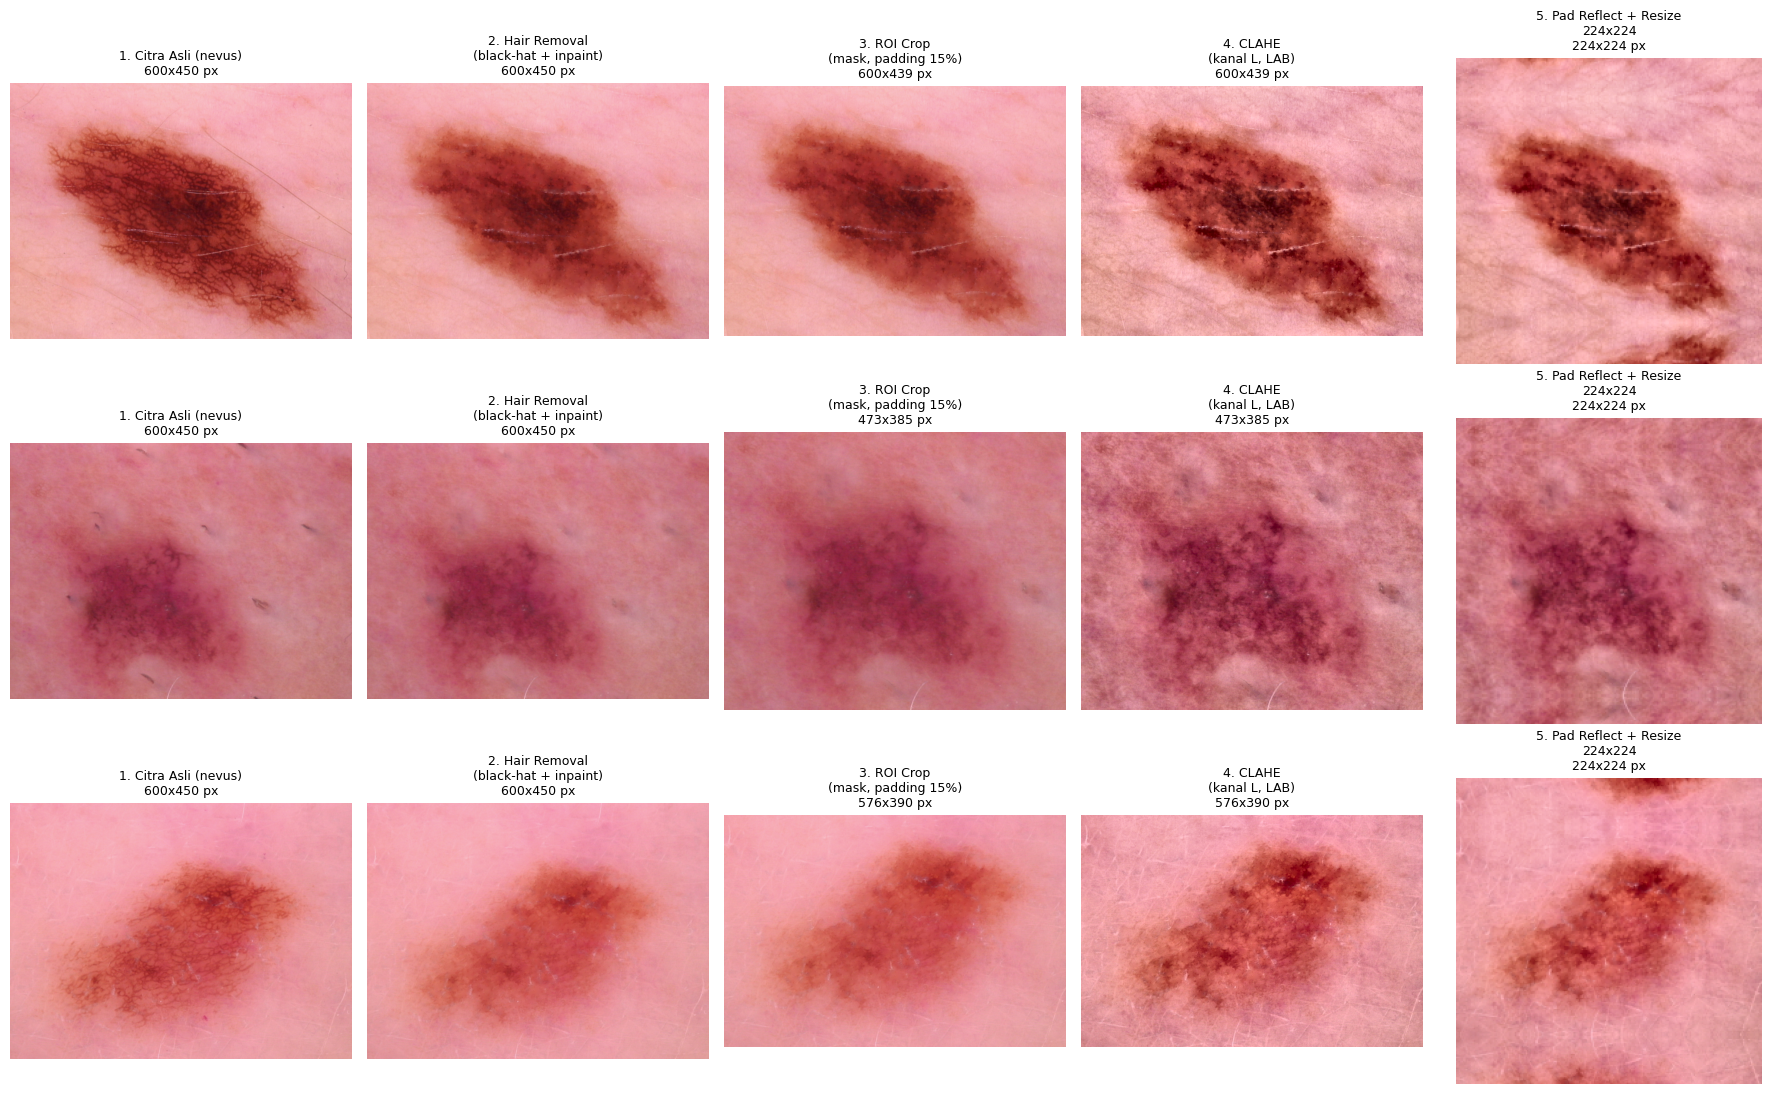

Grafik tahap preprocessing tersimpan di: /content/drive/MyDrive/riset_kanker_kulit/preprocessing_stages_irisan_12W12P.png


In [ ]:
# Bukti visual hasil preprocessing per langkah (3 citra pertama, dibaca langsung dari HDFS).
# Urutan kolom: Citra Asli -> Hair Removal -> Segmentasi (mask) -> ROI Crop -> CLAHE -> Pad & Resize 224
import matplotlib.pyplot as plt


def hdfs_cat(path):
    return subprocess.run(["hdfs", "dfs", "-cat", path], capture_output=True, check=True).stdout


STEP_TITLES = [
    "1. Citra Asli",
    "2. Hair Removal\n(black-hat + inpaint)",
    "3. Segmentasi Lesi\n(mask U-Net / dokter)",          # BARU
    "4. ROI Crop\n(bbox mask, padding 15%)",              # nomor bergeser
    "5. CLAHE\n(kanal L, LAB)",                           # nomor bergeser
    "6. Pad Reflect + Resize\n224x224",                   # nomor bergeser
]

print("[INFO] Menampilkan visualisasi 3 sampel citra pertama (hasil tiap langkah preprocessing):")
fig, axes = plt.subplots(3, 6, figsize=(21, 11))          # DIUBAH: 5 -> 6 kolom
for r_, (_, row_) in enumerate(df_unique.head(3).iterrows()):
    img_rgb = cv2.cvtColor(cv2.imdecode(np.frombuffer(hdfs_cat(row_["img_hdfs"]), np.uint8), cv2.IMREAD_COLOR),
                           cv2.COLOR_BGR2RGB)
    mask_gray = cv2.imdecode(np.frombuffer(hdfs_cat(row_["mask_hdfs"]), np.uint8), cv2.IMREAD_GRAYSCALE)

    step1 = img_rgb
    step2 = remove_hair(step1)
    step3_roi, mask_clean = crop_lesion_roi(step2, mask_gray, padding_ratio=0.15)   # DIUBAH: mask_clean tidak lagi dibuang
    step4 = apply_enhancement(step3_roi)
    step5 = pad_and_resize(step4, target_size=TARGET_SIZE, is_mask=False)

    panels = [step1, step2, mask_clean, step3_roi, step4, step5]                     # BARU: mask di posisi ke-3
    for c_, (im_, title_) in enumerate(zip(panels, STEP_TITLES)):
        if c_ == 0:
            title_ = f"{title_} ({row_['label']})"
        ax_ = axes[r_, c_]
        ax_.imshow(im_, cmap="gray" if c_ == 2 else None)                            # DIUBAH: mask ditampilkan grayscale
        ax_.set_title(f"{title_}\n{im_.shape[1]}x{im_.shape[0]} px", fontsize=9)
        ax_.axis("off")

plt.tight_layout()
vis_path = PROJECT_DIR / f"preprocessing_stages_{SCENARIO_NAME}.png"
plt.savefig(vis_path)
plt.show()
print(f"Grafik tahap preprocessing tersimpan di: {vis_path}")

In [20]:
# ==========================================================================
# INSTRUMENTASI METRIK SPARK (tidak mengubah konfigurasi / alur eksekusi)
#   1. Throughput   2. Latency & waktu eksekusi   3. Utilisasi sumber daya
#   4. Operasi shuffle (I/O & jaringan)   5. Skalabilitas & distribusi data (skewness)
# ==========================================================================
import json
import math
import threading
import urllib.request

import numpy as np
import psutil
from pyspark.accumulators import AccumulatorParam


class ListAccumulatorParam(AccumulatorParam):
    def zero(self, value):
        return []

    def addInPlace(self, v1, v2):
        v1.extend(v2)
        return v1


class ResourceMonitor:
    # Sampling CPU (total & per core) dan RAM sistem tiap interval_sec, serta RSS per kategori proses
    # tiap proc_interval_sec. start()/stop() dipanggil dari dalam run_distributed_preprocessing agar
    # jendela sampling persis sama dengan jendela timer.
    CATEGORIES = [
        ("executor_jvm", ("CoarseGrainedExecutorBackend",)),
        ("python_worker", ("pyspark.daemon",)),
        ("driver_jvm", ("org.apache.spark.deploy.SparkSubmit",)),
        ("am_jvm", ("ExecutorLauncher",)),
        ("hdfs_yarn_daemon", ("hdfs.server", "yarn.server")),
    ]

    def __init__(self, interval_sec=0.5, proc_interval_sec=5.0):
        self.interval_sec = interval_sec
        self.proc_interval_sec = proc_interval_sec
        self.keep_running = False
        self.cpu_records = []
        self.percpu_records = []
        self.mem_records = []
        self.peak_rss_mb = {}
        self.python_cpu_sec = 0.0
        self._thread = None

    def _snapshot_processes(self):
        rss = {name: 0 for name, _ in self.CATEGORIES}
        rss["notebook_kernel"] = 0
        py_cpu = 0.0
        me = os.getpid()
        for p in psutil.process_iter(["pid", "cmdline", "memory_info", "cpu_times"]):
            try:
                info = p.info
                mem = info["memory_info"].rss if info["memory_info"] else 0
                if info["pid"] == me:
                    rss["notebook_kernel"] += mem
                    continue
                cmd = " ".join(info["cmdline"] or [])
                for name, keys in self.CATEGORIES:
                    if any(k in cmd for k in keys):
                        rss[name] += mem
                        if name == "python_worker" and info["cpu_times"]:
                            py_cpu += info["cpu_times"].user + info["cpu_times"].system
                        break
            except (psutil.NoSuchProcess, psutil.AccessDenied):
                continue
        for name, v in rss.items():
            self.peak_rss_mb[name] = max(self.peak_rss_mb.get(name, 0.0), v / (1024 * 1024))
        self.python_cpu_sec = max(self.python_cpu_sec, py_cpu)

    def _loop(self):
        last_proc = 0.0
        while self.keep_running:
            self.cpu_records.append(psutil.cpu_percent(interval=None))
            self.percpu_records.append(psutil.cpu_percent(interval=None, percpu=True))
            self.mem_records.append(psutil.virtual_memory().used / (1024 * 1024))
            now = time.time()
            if now - last_proc >= self.proc_interval_sec:
                self._snapshot_processes()
                last_proc = now
            time.sleep(self.interval_sec)

    def start(self):
        self.cpu_records.clear()
        self.percpu_records.clear()
        self.mem_records.clear()
        self.peak_rss_mb = {}
        self.python_cpu_sec = 0.0
        psutil.cpu_percent(interval=None)                  # warmup: panggilan pertama selalu 0.0
        psutil.cpu_percent(interval=None, percpu=True)
        self.keep_running = True
        self._thread = threading.Thread(target=self._loop)
        self._thread.start()

    def stop(self):
        self.keep_running = False
        if self._thread is not None:
            self._thread.join()
            self._thread = None
        self._snapshot_processes()                         # snapshot akhir: CPU-detik worker Python

    def summary(self):
        n = len(self.cpu_records)
        percpu = np.asarray(self.percpu_records, dtype=float) if self.percpu_records else np.zeros((0, 1))
        return {
            "n_samples": n,
            "avg_cpu": sum(self.cpu_records) / n if n else 0.0,
            "peak_cpu": max(self.cpu_records) if n else 0.0,
            "avg_mem_mb": sum(self.mem_records) / n if n else 0.0,
            "peak_mem_mb": max(self.mem_records) if n else 0.0,
            "avg_per_core": percpu.mean(axis=0).tolist() if percpu.size else [],
            "peak_rss_mb": dict(self.peak_rss_mb),
            "python_cpu_sec": self.python_cpu_sec,
        }


def spark_rest_get(sc, path, timeout=10):
    # Spark REST API (UI driver). Mencoba URL UI driver, localhost, lalu proxy YARN (redirect diikuti otomatis).
    ui = (sc.uiWebUrl or "").rstrip("/")
    port = ui.rsplit(":", 1)[-1] if ui else "4040"
    bases = [b for b in [ui, f"http://localhost:{port}", f"http://localhost:8088/proxy/{sc.applicationId}"] if b]
    errors = []
    for b in bases:
        try:
            with urllib.request.urlopen(f"{b}/api/v1{path}", timeout=timeout) as r:
                return json.loads(r.read().decode("utf-8"))
        except Exception as e:
            errors.append(f"{b} -> {type(e).__name__}")
    raise RuntimeError("; ".join(errors))


def collect_job_metrics(sc, job_group, retries=15):
    # Metrik stage & task (shuffle, scheduler delay, GC) untuk job pada job_group tertentu.
    tracker = sc.statusTracker()
    stage_ids = []
    for jid in tracker.getJobIdsForGroup(job_group):
        info = tracker.getJobInfo(jid)
        if info is not None:
            stage_ids += [int(s) for s in info.stageIds]
    stage_ids = sorted(set(stage_ids))
    app = sc.applicationId
    stages, tasks = [], []
    for sid in stage_ids:
        st = None
        for _ in range(retries):                            # listener UI diperbarui asinkron
            data = spark_rest_get(sc, f"/applications/{app}/stages/{sid}")
            st = data[-1] if data else None
            if st is None or st["status"] == "SKIPPED" or (
                    st["status"] == "COMPLETE" and st["numCompleteTasks"] >= st["numTasks"]):
                break
            time.sleep(1)
        if st is None:
            continue
        stages.append({
            "stage_id": sid, "name": st["name"], "status": st["status"], "num_tasks": st["numTasks"],
            "shuffle_read_bytes": st.get("shuffleReadBytes", 0), "shuffle_read_records": st.get("shuffleReadRecords", 0),
            "shuffle_remote_bytes": st.get("shuffleRemoteBytesRead", 0), "shuffle_local_bytes": st.get("shuffleLocalBytesRead", 0),
            "shuffle_fetch_wait_ms": st.get("shuffleFetchWaitTime", 0),
            "shuffle_write_bytes": st.get("shuffleWriteBytes", 0), "shuffle_write_records": st.get("shuffleWriteRecords", 0),
            "shuffle_write_ms": st.get("shuffleWriteTime", 0) / 1e6,
            "spilled_mem_bytes": st.get("memoryBytesSpilled", 0), "spilled_disk_bytes": st.get("diskBytesSpilled", 0),
            "executor_run_ms": st.get("executorRunTime", 0),
        })
        if st["status"] == "SKIPPED":
            continue
        tl = spark_rest_get(sc, f"/applications/{app}/stages/{sid}/{st['attemptId']}/taskList?length=100000")
        for t in tl:
            tm = t.get("taskMetrics") or {}
            tasks.append({
                "stage_id": sid, "partition": t.get("partitionId"), "executor_id": t.get("executorId"),
                "duration_ms": t.get("duration", 0), "scheduler_delay_ms": t.get("schedulerDelay", 0),
                "deserialize_ms": tm.get("executorDeserializeTime", 0), "gc_ms": tm.get("jvmGcTime", 0),
                "run_ms": tm.get("executorRunTime", 0),
            })
    return {"stages": stages, "tasks": tasks}


def fetch_cache_disk_bytes(sc, retries=6):
    for _ in range(retries):
        try:
            rdds = spark_rest_get(sc, f"/applications/{sc.applicationId}/storage/rdd")
            used = int(sum(r.get("diskUsed", 0) for r in rdds))
            if used > 0:
                return used
        except Exception:
            return None
        time.sleep(1)
    return 0


def _dist(vals):
    a = np.asarray(vals, dtype=float)
    if a.size == 0:
        return {}
    m, sd = float(a.mean()), float(a.std())
    return {"min": float(a.min()), "max": float(a.max()), "mean": m, "std": sd,
            "median": float(np.median(a)),
            "cv_pct": sd / m * 100 if m else 0.0,
            "max_over_mean": float(a.max()) / m if m else 0.0}


def compute_spark_metrics(task_stats, wall_sec, num_workers, num_partitions, n_images,
                          mon, job_metrics, cache_disk_bytes, alloc_sec=None):
    ts = sorted(task_stats, key=lambda r: r["partition"])
    durs = [r["end"] - r["start"] for r in ts]
    imgs = [r["images"] for r in ts]
    byt = [r["bytes_in"] for r in ts]
    per_task_ips = [i / d if d > 0 else 0.0 for i, d in zip(imgs, durs)]

    read_ms = np.concatenate([np.asarray(r["read_ms"], float) for r in ts]) if ts else np.array([])
    proc_ms = np.concatenate([np.asarray(r["proc_ms"], float) for r in ts]) if ts else np.array([])
    lat_ms = read_ms + proc_ms
    measured_sec = float(lat_ms.sum()) / 1000.0
    total_task_sec = float(sum(durs))
    out_bytes = n_images * IMG_SIZE * IMG_SIZE * 3

    events = sorted([(r["start"], 1) for r in ts] + [(r["end"], -1) for r in ts], key=lambda e: (e[0], e[1]))
    cur = peak = 0
    for _, d in events:
        cur += d
        peak = max(peak, cur)
    pids = sorted({r["daemon_pid"] for r in ts})
    per_exec = []
    for k, pid in enumerate(pids):
        mine = [r for r in ts if r["daemon_pid"] == pid]
        per_exec.append({"executor": f"E{k + 1}", "tasks": len(mine),
                         "images": int(sum(r["images"] for r in mine)),
                         "busy_sec": float(sum(r["end"] - r["start"] for r in mine))})

    m = {
        "scenario": SCENARIO_NAME, "replicate": REPLICATE,
        "num_workers": num_workers, "num_partitions": num_partitions, "images": n_images,
        "wall_sec": wall_sec,
        "throughput": {
            "total_ips": n_images / wall_sec if wall_sec else 0.0,
            "per_core_ips": n_images / wall_sec / num_workers if wall_sec else 0.0,
            "per_task_ips": _dist(per_task_ips),
            "in_bytes": int(sum(byt)), "in_mbps": sum(byt) / wall_sec / 1e6 if wall_sec else 0.0,
            "out_bytes": int(out_bytes), "out_mbps": out_bytes / wall_sec / 1e6 if wall_sec else 0.0,
        },
        "latency": {
            "wall_sec": wall_sec, "yarn_alloc_sec": alloc_sec,
            "task_sec": _dist(durs),
            "per_image_ms": {**_dist(lat_ms),
                             "p50": float(np.percentile(lat_ms, 50)) if lat_ms.size else 0.0,
                             "p95": float(np.percentile(lat_ms, 95)) if lat_ms.size else 0.0,
                             "p99": float(np.percentile(lat_ms, 99)) if lat_ms.size else 0.0},
            "read_ms_mean": float(read_ms.mean()) if read_ms.size else 0.0,
            "proc_ms_mean": float(proc_ms.mean()) if proc_ms.size else 0.0,
            "overhead_sec": max(0.0, total_task_sec - measured_sec),
            "overhead_pct": max(0.0, total_task_sec - measured_sec) / total_task_sec * 100 if total_task_sec else 0.0,
        },
        "resource": mon,
        "skew": {
            "images_per_partition": _dist(imgs),
            "bytes_per_partition": _dist(byt),
            "task_sec": _dist(durs),
            "straggler_gap_sec": float(max(durs) - np.median(durs)) if durs else 0.0,
            "executors_used": len(pids), "executors_idle": max(0, num_workers - len(pids)),
            "peak_concurrent_tasks": peak, "expected_concurrent": min(num_partitions, num_workers),
            "waves_expected": math.ceil(num_partitions / num_workers),
            "total_task_sec": total_task_sec,
            "effective_parallelism": total_task_sec / wall_sec if wall_sec else 0.0,
            "slot_utilization_pct": total_task_sec / (wall_sec * num_workers) * 100 if wall_sec else 0.0,
            "per_executor": per_exec,
        },
        "shuffle": {"available": job_metrics is not None, "cache_disk_bytes": cache_disk_bytes,
                    "payload_if_shuffled_bytes": int(out_bytes)},
    }
    if job_metrics is not None:
        stg, tks = job_metrics["stages"], job_metrics["tasks"]
        m["shuffle"].update({
            "stages": stg,
            "read_bytes": sum(s["shuffle_read_bytes"] for s in stg),
            "write_bytes": sum(s["shuffle_write_bytes"] for s in stg),
            "read_records": sum(s["shuffle_read_records"] for s in stg),
            "write_records": sum(s["shuffle_write_records"] for s in stg),
            "remote_bytes": sum(s["shuffle_remote_bytes"] for s in stg),
            "local_bytes": sum(s["shuffle_local_bytes"] for s in stg),
            "fetch_wait_ms": sum(s["shuffle_fetch_wait_ms"] for s in stg),
            "spilled_bytes": sum(s["spilled_mem_bytes"] + s["spilled_disk_bytes"] for s in stg),
        })
        m["latency"]["spark_tasks"] = len(tks)
        m["latency"]["sched_delay_ms_mean"] = float(np.mean([t["scheduler_delay_ms"] for t in tks])) if tks else 0.0
        m["latency"]["deserialize_ms_mean"] = float(np.mean([t["deserialize_ms"] for t in tks])) if tks else 0.0
        run_ms = sum(t["run_ms"] for t in tks)
        m["resource"]["gc_ms_total"] = int(sum(t["gc_ms"] for t in tks))
        m["resource"]["gc_pct_of_run"] = sum(t["gc_ms"] for t in tks) / run_ms * 100 if run_ms else 0.0
        m["skew"]["spark_executor_ids"] = sorted({str(t["executor_id"]) for t in tks if t["stage_id"] == max(s["stage_id"] for s in stg)})
    return m


def _b(n):
    n = float(n)
    for unit in ["B", "KB", "MB", "GB"]:
        if abs(n) < 1024 or unit == "GB":
            return f"{n:,.1f} {unit}" if unit != "B" else f"{int(n):,} B"
        n /= 1024


def print_spark_report(m, task_stats):
    ts = sorted(task_stats, key=lambda r: r["partition"])
    W, P, N = m["num_workers"], m["num_partitions"], m["images"]
    line, dline = "=" * 72, "-" * 72
    print("\n" + line)
    print(f"=== LAPORAN BEBAN KERJA PRAPEMROSESAN CITRA (SPARK: {W} WORKER, {P} PARTISI) ===")
    print(line)
    for r in ts:
        d = r["end"] - r["start"]
        print(f"Spark Task [Partisi {r['partition']:2d}] -> Memproses {r['images']:,} citra dalam {d:.2f} detik "
              f"({r['images'] / d if d else 0:.1f} citra/dtk)")
    print(dline)
    print(f"Jumlah Worker (Core)   : {W}")
    print(f"Jumlah Partisi Data    : {P}")
    print(f"Total Citra Diproses   : {N:,} citra")
    print(f"Total Waktu Eksekusi   : {m['wall_sec'] / 60:.2f} menit ({m['wall_sec']:.2f} detik)")
    print(f"Throughput Rata-Rata   : {m['throughput']['total_ips']:.2f} citra/detik")
    print(line)

    t, l, r_, s, k = m["throughput"], m["latency"], m["resource"], m["shuffle"], m["skew"]

    print("\n[1] METRIK THROUGHPUT (KAPASITAS PEMROSESAN)")
    print(dline)
    print(f"Throughput total              : {t['total_ips']:.2f} citra/detik")
    print(f"Throughput per executor/core  : {t['per_core_ips']:.2f} citra/detik (total / {W} executor)")
    d = t["per_task_ips"]
    print(f"Throughput per task           : min {d['min']:.2f} | rata-rata {d['mean']:.2f} | maks {d['max']:.2f} citra/detik")
    print(f"Data masuk (HDFS -> executor) : {_b(t['in_bytes'])} (citra asli + mask) | {t['in_mbps']:.2f} MB/detik")
    print(f"Data keluar (array 224x224x3) : {_b(t['out_bytes'])} | {t['out_mbps']:.2f} MB/detik")

    print("\n[2] METRIK LATENCY DAN EXECUTION TIME")
    print(dline)
    print(f"Waktu eksekusi total (terukur): {l['wall_sec']:.2f} detik")
    if l.get("yarn_alloc_sec") is not None:
        print(f"Waktu alokasi container YARN  : {l['yarn_alloc_sec']:.2f} detik (di luar jendela terukur)")
    d = l["task_sec"]
    print(f"Durasi task (detik)           : min {d['min']:.2f} | rata-rata {d['mean']:.2f} | maks {d['max']:.2f} | std {d['std']:.2f}")
    d = l["per_image_ms"]
    print(f"Latensi per citra (ms)        : rata-rata {d['mean']:.1f} | P50 {d['p50']:.1f} | P95 {d['p95']:.1f} | P99 {d['p99']:.1f} | maks {d['max']:.1f}")
    tot = l["read_ms_mean"] + l["proc_ms_mean"]
    print(f"Komposisi latensi per citra   : baca HDFS {l['read_ms_mean']:.1f} ms ({l['read_ms_mean'] / tot * 100 if tot else 0:.0f}%) | "
          f"komputasi OpenCV {l['proc_ms_mean']:.1f} ms ({l['proc_ms_mean'] / tot * 100 if tot else 0:.0f}%)")
    print(f"Overhead non-citra dalam task : {l['overhead_sec']:.1f} detik-task ({l['overhead_pct']:.1f}%) "
          f"(serialisasi Python->JVM, persist DISK_ONLY, init HDFS)")
    if s["available"]:
        print(f"Spark scheduler delay (rata2) : {l['sched_delay_ms_mean']:.1f} ms/task | deserialisasi task {l['deserialize_ms_mean']:.1f} ms/task "
              f"({l['spark_tasks']} task tercatat Spark)")
    else:
        print("Spark scheduler delay         : tidak tersedia (REST API Spark UI tidak dapat diakses)")

    print("\n[3] METRIK PEMANFAATAN SUMBER DAYA (RESOURCE UTILIZATION)")
    print(dline)
    print(f"CPU sistem                    : rata-rata {r_['avg_cpu']:.1f}% | puncak {r_['peak_cpu']:.1f}% ({r_['n_samples']} sampel)")
    pc = r_["avg_per_core"]
    if pc:
        active = sum(1 for x in pc if x >= 50)
        print(f"CPU per core (rata-rata)      : {active} dari {len(pc)} core >= 50% | " + " ".join(f"{x:.0f}" for x in pc))
    print(f"RAM sistem terpakai           : rata-rata {r_['avg_mem_mb']:,.0f} MB | puncak {r_['peak_mem_mb']:,.0f} MB")
    rss = r_["peak_rss_mb"]
    print("Puncak RSS per kategori (MB)  : " + " | ".join(f"{k_} {v:,.0f}" for k_, v in rss.items()) +
          "  (RSS dijumlahkan; halaman bersama bisa terhitung ganda)")
    tt = k["total_task_sec"]
    print(f"CPU-detik worker Python       : {r_['python_cpu_sec']:.1f} detik dari {tt:.1f} detik-task "
          f"(efisiensi CPU {r_['python_cpu_sec'] / tt * 100 if tt else 0:.0f}%)")
    if "gc_pct_of_run" in r_:
        print(f"GC JVM executor               : {r_['gc_ms_total']:,} ms ({r_['gc_pct_of_run']:.2f}% dari executor run time)")

    print("\n[4] METRIK OPERASI SHUFFLE (I/O & JARINGAN)")
    print(dline)
    if s["available"]:
        for st in s["stages"]:
            print(f"Stage {st['stage_id']:>2} [{st['status']}] {st['name'][:38]:<38} task={st['num_tasks']:<3} "
                  f"shuffle read {_b(st['shuffle_read_bytes'])} | write {_b(st['shuffle_write_bytes'])}")
        print(f"Total shuffle write           : {_b(s['write_bytes'])} ({s['write_records']:,} record)")
        print(f"Total shuffle read            : {_b(s['read_bytes'])} ({s['read_records']:,} record) | "
              f"remote {_b(s['remote_bytes'])} | lokal {_b(s['local_bytes'])}")
        print(f"Fetch wait shuffle            : {s['fetch_wait_ms']:,} ms | spill memori+disk: {_b(s['spilled_bytes'])}")
        ratio = s["payload_if_shuffled_bytes"] / max(1, s["write_bytes"])
        print(f"Payload citra yang dihindari  : {_b(s['payload_if_shuffled_bytes'])} tidak di-shuffle (hanya path) -> "
              f"{ratio:,.0f}x lebih kecil dari shuffle citra")
    else:
        print("Metrik shuffle tidak tersedia: REST API Spark UI tidak dapat diakses dari notebook.")
    if s["cache_disk_bytes"] is not None:
        print(f"Cache DISK_ONLY (RDD hasil)   : {_b(s['cache_disk_bytes'])} di disk executor")
    print(f"Baca HDFS oleh executor       : {_b(t['in_bytes'])} | tulis hasil: shard .npz pada Fase 6")

    print("\n[5] METRIK SKALABILITAS DAN DISTRIBUSI DATA (DATA SKEWNESS)")
    print(dline)
    d = k["images_per_partition"]
    print(f"Citra per partisi             : min {d['min']:,.0f} | maks {d['max']:,.0f} | rata-rata {d['mean']:,.1f} | "
          f"CV {d['cv_pct']:.2f}% | maks/rata-rata {d['max_over_mean']:.3f}")
    d = k["bytes_per_partition"]
    print(f"Byte input per partisi        : min {_b(d['min'])} | maks {_b(d['max'])} | CV {d['cv_pct']:.2f}% | maks/rata-rata {d['max_over_mean']:.3f}")
    d = k["task_sec"]
    print(f"Durasi task                   : CV {d['cv_pct']:.2f}% | maks/rata-rata {d['max_over_mean']:.3f} | "
          f"selisih straggler (maks - median) {k['straggler_gap_sec']:.2f} detik")
    print(f"Executor yang menjalankan task: {k['executors_used']} dari {W} (menganggur: {k['executors_idle']})")
    print(f"Task paralel puncak           : {k['peak_concurrent_tasks']} (diharapkan min(partisi, executor) = {k['expected_concurrent']})")
    print(f"Gelombang task                : diharapkan {k['waves_expected']} = ceil({P}/{W})")
    print(f"Paralelisme efektif           : {k['effective_parallelism']:.2f} task rata-rata aktif (jumlah detik-task / waktu eksekusi)")
    print(f"Pemanfaatan slot executor     : {k['slot_utilization_pct']:.1f}% dari {W} slot")
    print("Beban per executor            :")
    for e in k["per_executor"]:
        print(f"   {e['executor']:<4} task={e['tasks']} | citra={e['images']:,} | sibuk={e['busy_sec']:.1f} detik")
    print(line + "\n")

In [21]:
def run_distributed_preprocessing(spark, manifest_rows, num_partitions, monitor=None):
    sc = spark.sparkContext
    expected_total = len(manifest_rows)
    n_exec_now = sc._jsc.sc().getExecutorMemoryStatus().size() - 1
    print(f"[INFO] Spark aktif: master={sc.master} | executor aktif={n_exec_now} | partisi RDD={num_partitions}")
    print(f"[INFO] Memproses {expected_total:,} gambar secara paralel menggunakan Spark...")

    # 1. Distribusikan PATH (string ringan) ke partisi worker, bukan byte citra
    paths_rdd = sc.parallelize(manifest_rows).repartition(num_partitions)

    java_home = os.environ["JAVA_HOME"]
    hadoop_home = str(HADOOP_HOME)
    hadoop_classpath = subprocess.run(
        [f"{hadoop_home}/bin/hadoop", "classpath", "--glob"],
        capture_output=True, text=True, check=True,
    ).stdout.strip()

    # Akumulator: kegagalan + statistik per task (untuk laporan beban kerja & skewness)
    error_acc = sc.accumulator(0)
    stats_acc = sc.accumulator([], ListAccumulatorParam())

    # 2. Eksekusi preprocessing per partisi di worker
    def preprocess_partition(rows):
        import os
        import time
        os.environ["JAVA_HOME"] = java_home
        os.environ["HADOOP_HOME"] = hadoop_home
        os.environ["LD_LIBRARY_PATH"] = f"{hadoop_home}/lib/native:{java_home}/lib/server"
        os.environ["CLASSPATH"] = hadoop_classpath
        os.environ["ARROW_LIBHDFS_DIR"] = f"{hadoop_home}/lib/native"

        os.environ["LIBHDFS_OPTS"] = "-Xms32m -Xmx384m -XX:+UseSerialGC"

        import cv2
        cv2.setNumThreads(1)
        import pyarrow.fs as pafs
        from pyspark import TaskContext

        t_task_start = time.time()
        hdfs = pafs.HadoopFileSystem("localhost", port=9000)

        n_ok = 0
        n_err = 0
        bytes_in = 0
        read_ms, proc_ms = [], []
        for image_id, img_path, mask_path, label in rows:
            try:
                t_a = time.perf_counter()
                with hdfs.open_input_stream(img_path, buffer_size=65536) as f:
                    img_bytes = f.read()
                with hdfs.open_input_stream(mask_path, buffer_size=65536) as f:
                    mask_bytes = f.read()
                t_b = time.perf_counter()

                array = process_image_bytes(img_bytes, mask_bytes)
                t_c = time.perf_counter()

                read_ms.append(round((t_b - t_a) * 1000, 3))
                proc_ms.append(round((t_c - t_b) * 1000, 3))
                bytes_in += len(img_bytes) + len(mask_bytes)
                n_ok += 1
                yield (array, label, image_id)
            except Exception as exc:
                n_err += 1
                error_acc.add(1)
                print(f"Error memproses citra {image_id} ({img_path}): {exc}")

        stats_acc.add([{
            "partition": TaskContext.get().partitionId(), "daemon_pid": os.getppid(), "pid": os.getpid(),
            "images": n_ok, "errors": n_err, "bytes_in": bytes_in,
            "start": t_task_start, "end": time.time(), "read_ms": read_ms, "proc_ms": proc_ms,
        }])

    processed_rdd = (
        paths_rdd
        .mapPartitions(preprocess_partition)
        .persist(StorageLevel.MEMORY_AND_DISK)
    )

    # 3. Jendela pengukuran: hanya materialisasi RDD (eksekusi nyata).
    #    Monitor sumber daya dibuka dan ditutup persis pada batas yang sama dengan timer.
    job_group = "preprocessing_timed"
    sc.setJobGroup(job_group, f"preprocessing {SCENARIO_NAME}")
    if monitor is not None:
        monitor.start()
    start_time = time.time()
    image_count = processed_rdd.count()
    elapsed_sec = time.time() - start_time
    if monitor is not None:
        monitor.stop()
    sc._jsc.clearJobGroup()          # PySpark tidak punya clearJobGroup(); panggil lewat JavaSparkContext

    partition_sizes = processed_rdd.mapPartitions(lambda it: [sum(1 for _ in it)]).collect()
    failed = error_acc.value
    task_stats = list(stats_acc.value)

    print("Prapemrosesan terdistribusi selesai!")
    print(f"Jumlah partisi aktual: {len(partition_sizes)} (target: {num_partitions})")
    print(f"Distribusi citra per partisi: {partition_sizes}")
    if len(task_stats) != num_partitions:
        print(f"[PERINGATAN] Statistik task tercatat {len(task_stats)} (diharapkan {num_partitions}); "
              f"kemungkinan ada task yang diulang (retry).")
    if failed:
        raise RuntimeError(
            f"{failed} citra gagal diproses di executor ({image_count}/{expected_total} berhasil). "
            f"Seluruh {expected_total} citra wajib berhasil agar sama dengan baseline; "
            f"periksa log executor (yarn logs) untuk detail."
        )
    print(f"Seluruh {image_count} citra berhasil diproses tanpa kegagalan.")

    return processed_rdd, elapsed_sec, image_count, task_stats, job_group

In [22]:
monitor = ResourceMonitor()

processed_rdd, preprocessing_time_sec, image_count, task_stats, job_group = run_distributed_preprocessing(
    spark, spark_manifest_rows, NUM_PARTITIONS, monitor=monitor
)

mon = monitor.summary()
avg_cpu = mon["avg_cpu"]
avg_mem = mon["avg_mem_mb"]

# Metrik tingkat Spark (shuffle, scheduler delay, GC) dari REST API UI driver
job_metrics = None
try:
    job_metrics = collect_job_metrics(spark.sparkContext, job_group)
except Exception as exc:
    print(f"[PERINGATAN] Metrik REST Spark tidak dapat diambil ({exc}). Bagian shuffle/scheduler tidak ditampilkan.")
cache_disk_bytes = fetch_cache_disk_bytes(spark.sparkContext)

spark_metrics = compute_spark_metrics(
    task_stats, preprocessing_time_sec, NUM_WORKERS, NUM_PARTITIONS, image_count,
    mon, job_metrics, cache_disk_bytes,
    alloc_sec=yarn_alloc_time_sec if "yarn_alloc_time_sec" in globals() else None,
)
print_spark_report(spark_metrics, task_stats)

metrics_path = PROJECT_DIR / f"spark_metrics_{SCENARIO_NAME}_r{REPLICATE}.json"
with open(metrics_path, "w") as f:
    json.dump(spark_metrics, f, indent=1, default=float)
print(f"Metrik lengkap tersimpan di: {metrics_path}")

log_result("preprocessing", preprocessing_time_sec, image_count=image_count,
           avg_cpu=avg_cpu, avg_mem=avg_mem)

assert image_count == len(spark_manifest_rows), "Jumlah citra terproses != jumlah tugas manifest."

sample_array, sample_label, sample_id = processed_rdd.first()
print(f"Bentuk dimensi array (Shape): {sample_array.shape}")
print(f"Tipe data: {sample_array.dtype}")
print(f"Nilai piksel minimum: {sample_array.min()}, maksimum: {sample_array.max()}")
print(f"ID Citra: {sample_id}, Label numerik: {sample_label} ({class_names[sample_label]})")

assert sample_array.shape == (IMG_SIZE, IMG_SIZE, 3), "Dimensi citra tidak sesuai spesifikasi 224x224x3!"
assert sample_array.dtype == np.uint8, "Tipe data citra harus uint8!"
print("Sanity check prapemrosesan berhasil.")
print(f"\n[INFO] Selesai! Sebanyak {image_count:,} citra ROI tersegmentasi siap digunakan.")

[INFO] Spark aktif: master=yarn | executor aktif=12 | partisi RDD=12
[INFO] Memproses 24,466 gambar secara paralel menggunakan Spark...
Prapemrosesan terdistribusi selesai!
Jumlah partisi aktual: 12 (target: 12)
Distribusi citra per partisi: [2046, 2030, 2046, 2048, 2046, 2046, 2038, 2030, 2030, 2046, 2030, 2030]
Seluruh 24466 citra berhasil diproses tanpa kegagalan.

=== LAPORAN BEBAN KERJA PRAPEMROSESAN CITRA (SPARK: 12 WORKER, 12 PARTISI) ===
Spark Task [Partisi  0] -> Memproses 2,046 citra dalam 420.65 detik (4.9 citra/dtk)
Spark Task [Partisi  1] -> Memproses 2,030 citra dalam 430.36 detik (4.7 citra/dtk)
Spark Task [Partisi  2] -> Memproses 2,046 citra dalam 420.45 detik (4.9 citra/dtk)
Spark Task [Partisi  3] -> Memproses 2,048 citra dalam 421.31 detik (4.9 citra/dtk)
Spark Task [Partisi  4] -> Memproses 2,046 citra dalam 425.98 detik (4.8 citra/dtk)
Spark Task [Partisi  5] -> Memproses 2,046 citra dalam 426.46 detik (4.8 citra/dtk)
Spark Task [Partisi  6] -> Memproses 2,038 cit

## Fase 6 - Sharding ke HDFS dan Pengumpulan Data ke Driver
Executor menulis shard `.npz` kecil ke HDFS (memori per task dibatasi `SHARD_SIZE`, bukan ukuran partisi). Setelah itu Spark dihentikan, dan driver membaca shard satu per satu ke array NumPy uint8. Array dirakit berdasarkan `image_id` mengikuti urutan manifest, sehingga urutan sampel train/val/test **sama persis dengan baseline** (penting untuk urutan shuffle yang ber-seed).

In [23]:
def assemble_arrays_from_shards(shard_dir, split_dfs, class_to_id, img_size):
    "Rakit X/y per split dari shard .npz, ditempatkan menurut urutan baris manifest (berdasar image_id)."
    from collections import defaultdict

    X = {s: np.empty((len(d), img_size, img_size, 3), dtype=np.uint8) for s, d in split_dfs.items()}
    y = {s: d["label"].map(class_to_id).to_numpy() for s, d in split_dfs.items()}
    filled = {s: np.zeros(len(d), dtype=bool) for s, d in split_dfs.items()}

    pos_map = defaultdict(list)
    for s, d in split_dfs.items():
        for i, iid in enumerate(d["image_id"].astype(str)):
            pos_map[iid].append((s, i))

    n_shards = 0
    for shard_path in sorted(Path(shard_dir).glob("*.npz")):
        with np.load(shard_path) as z:
            xs, ys, ids = z["x"], z["y"], z["ids"]
        for k in range(len(ids)):
            for s, i in pos_map.get(str(ids[k]), []):
                if int(ys[k]) != int(y[s][i]):
                    raise RuntimeError(f"Label shard != manifest untuk {ids[k]} (split {s}).")
                X[s][i] = xs[k]
                filled[s][i] = True
        del xs, ys, ids
        shard_path.unlink()          # hemat disk: shard yang sudah dimuat langsung dihapus
        n_shards += 1

    for s in split_dfs:
        missing = int((~filled[s]).sum())
        if missing:
            raise RuntimeError(f"Split '{s}': {missing} sampel tidak ditemukan di shard.")
    return X, y, n_shards

In [24]:
import shutil

# =============================================================================
# TAHAP A - Executor menulis SHARD kecil ke HDFS.
# =============================================================================
SHARD_SIZE = 64                              # 64 citra x 150 KiB (uint8) = ~9.6 MiB per shard
SHARD_HDFS_DIR = HDFS_SHARD_DIR

_java_home = os.environ["JAVA_HOME"]
_hadoop_home = str(HADOOP_HOME)
_hadoop_classpath = subprocess.run(
    [f"{_hadoop_home}/bin/hadoop", "classpath", "--glob"],
    capture_output=True, text=True, check=True,
).stdout.strip()
_shard_dir, _shard_size = SHARD_HDFS_DIR, SHARD_SIZE


def write_shards(part_idx, rows):
    import io
    import os
    import numpy as np

    os.environ["JAVA_HOME"] = _java_home
    os.environ["HADOOP_HOME"] = _hadoop_home
    os.environ["LD_LIBRARY_PATH"] = f"{_hadoop_home}/lib/native:{_java_home}/lib/server"
    os.environ["CLASSPATH"] = _hadoop_classpath
    os.environ["ARROW_LIBHDFS_DIR"] = f"{_hadoop_home}/lib/native"

    os.environ["LIBHDFS_OPTS"] = "-Xms32m -Xmx384m -XX:+UseSerialGC" #hapus ini jika eror

    import pyarrow.fs as pafs

    hdfs = pafs.HadoopFileSystem("localhost", port=9000)

    xs, ys, ids = [], [], []
    n_shards = 0
    n_rows = 0

    def flush():
        nonlocal xs, ys, ids, n_shards, n_rows
        if not xs:
            return
        buf = io.BytesIO()
        np.savez(buf, x=np.stack(xs), y=np.asarray(ys, dtype=np.int32), ids=np.asarray(ids))
        # Nama deterministik: jika task di-retry, file lama ditimpa (idempotent).
        with hdfs.open_output_stream(f"{_shard_dir}/p{part_idx:03d}_s{n_shards:05d}.npz", buffer_size=65536) as out:
            out.write(buf.getbuffer())
        n_rows += len(xs)
        n_shards += 1
        xs, ys, ids = [], [], []

    for arr, lbl, iid in rows:
        xs.append(arr)
        ys.append(lbl)
        ids.append(iid)
        if len(xs) >= _shard_size:
            flush()
    flush()
    yield (part_idx, n_shards, n_rows)


subprocess.run(["hdfs", "dfs", "-rm", "-r", "-f", "-skipTrash", SHARD_HDFS_DIR], capture_output=True)
subprocess.run(["hdfs", "dfs", "-mkdir", "-p", SHARD_HDFS_DIR], check=True)

print(f"Executor menulis shard ({SHARD_SIZE} citra/shard) ke HDFS: {SHARD_HDFS_DIR}")
_t0 = time.time()
shard_report = sorted(processed_rdd.mapPartitionsWithIndex(write_shards).collect())
shard_write_sec = time.time() - _t0
_rows_written = sum(r[2] for r in shard_report)
print(f"Selesai dalam {shard_write_sec:.1f} detik | "
      f"{sum(r[1] for r in shard_report)} shard | {_rows_written} citra")
for _p, _ns, _nr in shard_report:
    print(f"  - partisi {_p}: {_nr} citra -> {_ns} shard")

assert _rows_written == image_count, (
    f"Jumlah citra di shard ({_rows_written}) != hasil preprocessing ({image_count})."
)
log_result("shard_write", shard_write_sec, image_count=_rows_written)

# Cache DISK_ONLY tidak diperlukan lagi -> bebaskan disk sebelum shard diunduh ke lokal.
try:
    processed_rdd.unpersist(blocking=True)
    print("Cache processed_rdd berhasil dibersihkan.")
except Exception as e:
    print(f"Pembersihan cache: {e}")

# Tugas Spark selesai. Lepas RAM executor + JVM driver sebelum training di GPU.
spark.stop()
print("SparkSession dihentikan; RAM executor dilepas.")

# =============================================================================
# TAHAP B - Driver membaca shard ke array NumPy (urutan = urutan manifest baseline).
# =============================================================================
print("\nMengumpulkan data Train, Val, dan Test dari shard ke memori driver...")
_t1 = time.time()

LOCAL_SHARD_DIR = INSTALL_DIR / "shards_local"
if LOCAL_SHARD_DIR.exists():
    shutil.rmtree(LOCAL_SHARD_DIR)
subprocess.run(["hdfs", "dfs", "-get", SHARD_HDFS_DIR, str(LOCAL_SHARD_DIR)], check=True)

split_dfs = {s: df_final[df_final["split"] == s].reset_index(drop=True) for s in ["train", "val", "test"]}
X_all, y_all, _n_shards = assemble_arrays_from_shards(LOCAL_SHARD_DIR, split_dfs, class_to_id, IMG_SIZE)

X_train, y_train, train_df = X_all["train"], y_all["train"], split_dfs["train"]
X_val, y_val, val_df = X_all["val"], y_all["val"], split_dfs["val"]
X_test, y_test, test_df = X_all["test"], y_all["test"], split_dfs["test"]
del X_all, y_all

collect_driver_sec = time.time() - _t1
print(f"Pengumpulan data selesai dalam {collect_driver_sec:.1f} detik ({_n_shards} shard).")
for name, X, y in [("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
    print(f"{name:<5}: {X.shape} | distribusi kelas: {np.bincount(y).tolist()}")

log_result("collect_driver", collect_driver_sec, image_count=len(X_train) + len(X_val) + len(X_test))

# Bersihkan shard sementara (lokal + HDFS)
shutil.rmtree(LOCAL_SHARD_DIR, ignore_errors=True)
subprocess.run(["hdfs", "dfs", "-rm", "-r", "-f", "-skipTrash", SHARD_HDFS_DIR], capture_output=True)
gc.collect()

_total_mb = (X_train.nbytes + X_val.nbytes + X_test.nbytes) / (1024 ** 2)
print(f"Total memori array di driver (uint8): {_total_mb:.1f} MB (~{_total_mb / 1024:.2f} GB)")

Executor menulis shard (64 citra/shard) ke HDFS: /user/skincancer/irisan_shards
Selesai dalam 15.4 detik | 384 shard | 24466 citra
  - partisi 0: 2046 citra -> 32 shard
  - partisi 1: 2030 citra -> 32 shard
  - partisi 2: 2046 citra -> 32 shard
  - partisi 3: 2048 citra -> 32 shard
  - partisi 4: 2046 citra -> 32 shard
  - partisi 5: 2046 citra -> 32 shard
  - partisi 6: 2038 citra -> 32 shard
  - partisi 7: 2030 citra -> 32 shard
  - partisi 8: 2030 citra -> 32 shard
  - partisi 9: 2046 citra -> 32 shard
  - partisi 10: 2030 citra -> 32 shard
  - partisi 11: 2030 citra -> 32 shard
[LOG] shard_write (irisan_12W12P, replikasi 2) -> results.csv
Cache processed_rdd berhasil dibersihkan.
SparkSession dihentikan; RAM executor dilepas.

Mengumpulkan data Train, Val, dan Test dari shard ke memori driver...
Pengumpulan data selesai dalam 17.9 detik (384 shard).
train: (19713, 224, 224, 3) | distribusi kelas: [4705, 12404, 2604]
val  : (2410, 224, 224, 3) | distribusi kelas: [594, 1462, 354]
te

## Fase 7 - Pelatihan Terpusat GPU (ConvNeXt-Tiny, Resep Baseline) & Evaluasi
Sel training dan evaluasi di bawah adalah sel baseline `00_baseline_convnext_tiny_ak84` yang dipakai apa adanya (arsitektur, augmentasi, AdamW, cosine LR, class weight, seed 42, dua fase 4 + maks 15 epoch). Perbedaan hanya: nama checkpoint per skenario/replikasi, serta perekaman waktu dan metrik ke `results.csv`. Seleksi model berdasarkan Val Macro-F1; test set dievaluasi sekali di akhir.

In [25]:
# ==========================================
# EXP 5-C: CONVNEXT-TINY (timm) + PREPROCESSING ROI U-NET
# RESEP LATIH: 2 FASE, COSINE LR, CLASS WEIGHT, AUGMENTASI WARNA
# ==========================================
import random
import time
import numpy as np
import torch
import torch.nn as nn
import timm
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from sklearn.metrics import f1_score, balanced_accuracy_score, roc_auc_score

CFG = dict(arch="convnext_tiny", img=224, bs=64, wd=1e-4, workers=4, seed=42,
           stage1_lr=3e-4, stage1_epochs=4, stage2_lr=2e-5, stage2_epochs=15, patience=4)

dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = dev.type == "cuda"

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

seed_all(CFG["seed"])
print("Device:", dev, torch.cuda.get_device_name(0) if AMP else "", "| torch", torch.__version__, "| timm", timm.__version__)


class ColorTemp:
    """Geser suhu warna: R dikali g, B dibagi g, g ~ U(1-s, 1+s)."""
    def __init__(self, s):
        self.s = s

    def __call__(self, im):
        g = random.uniform(1 - self.s, 1 + self.s)
        r, gg, b = im.split()
        return Image.merge("RGB", (r.point(lambda v: min(255, v * g)), gg, b.point(lambda v: min(255, v / g))))


class ArrayDS(Dataset):
    def __init__(self, X, y, tf):
        self.X, self.y, self.tf = X, y, tf

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        return self.tf(Image.fromarray(self.X[i])), int(self.y[i])


K = len(class_names)
model = timm.create_model(CFG["arch"], pretrained=True, num_classes=K).to(dev)
pc = model.pretrained_cfg
norm = T.Normalize(pc.get("mean", (0.485, 0.456, 0.406)), pc.get("std", (0.229, 0.224, 0.225)))

tf_train = T.Compose([
    T.RandomHorizontalFlip(), T.RandomVerticalFlip(), T.RandomRotation(20),
    T.ColorJitter(0.3, 0.3, 0.3, 0.03), ColorTemp(0.1), T.ToTensor(), norm,
])
tf_eval = T.Compose([T.ToTensor(), norm])

gen = torch.Generator().manual_seed(CFG["seed"])
mk = lambda X, y, tf, shuffle: DataLoader(
    ArrayDS(X, y, tf), CFG["bs"], shuffle=shuffle, drop_last=shuffle,
    num_workers=CFG["workers"], pin_memory=AMP, persistent_workers=True, generator=gen)
dl_train, dl_val, dl_test = mk(X_train, y_train, tf_train, True), mk(X_val, y_val, tf_eval, False), mk(X_test, y_test, tf_eval, False)

cnt = np.bincount(y_train, minlength=K)
class_w = torch.tensor(cnt.sum() / (K * cnt), dtype=torch.float32, device=dev)
print("Bobot kelas:", {c: round(float(w), 3) for c, w in zip(class_names, class_w.cpu())})
criterion = nn.CrossEntropyLoss(weight=class_w)


@torch.no_grad()
def predict(loader):
    model.eval()
    out = []
    for x, _ in loader:
        with torch.autocast(dev.type, enabled=AMP):
            out.append(model(x.to(dev, non_blocking=True)).float().softmax(1).cpu())
    return torch.cat(out).numpy()


def freeze_backbone():
    for p in model.parameters():
        p.requires_grad = False
    for p in model.get_classifier().parameters():
        p.requires_grad = True


def unfreeze_all():
    for p in model.parameters():
        p.requires_grad = True


best_model_path = str(PROJECT_DIR / f"best_convnext_tiny_{SCENARIO_NAME}_r{REPLICATE}.pt")
print("Checkpoint terbaik:", best_model_path)

fe, fte = CFG["stage1_epochs"], CFG["stage2_epochs"]
best, bad, history = -1.0, 0, []
t_start = time.time()

for ep in range(fe + fte):
    stage = 1 if ep < fe else 2
    if ep == 0:
        freeze_backbone()
        opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=CFG["stage1_lr"], weight_decay=CFG["wd"])
        sched = None
        scaler = torch.amp.GradScaler(dev.type, enabled=AMP)
        print(f"[INFO] Fase 1: head saja, {fe} epoch, LR {CFG['stage1_lr']}")
    elif ep == fe:
        unfreeze_all()
        opt = torch.optim.AdamW(model.parameters(), lr=CFG["stage2_lr"], weight_decay=CFG["wd"])
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=fte)
        scaler = torch.amp.GradScaler(dev.type, enabled=AMP)
        bad = 0
        print(f"[INFO] Fase 2: fine-tuning penuh, maks {fte} epoch, LR {CFG['stage2_lr']} + cosine")

    model.train() if stage == 2 else model.eval()
    t0, total_loss, n = time.time(), 0.0, 0
    for x, y in dl_train:
        x, y = x.to(dev, non_blocking=True), y.to(dev, non_blocking=True)
        opt.zero_grad(set_to_none=True)
        with torch.autocast(dev.type, enabled=AMP):
            loss = criterion(model(x), y)
        scaler.scale(loss).backward()
        scaler.step(opt)
        scaler.update()
        total_loss += loss.item() * len(y)
        n += len(y)
    if sched:
        sched.step()

    P = predict(dl_val)
    pred = P.argmax(1)
    val_acc = float((pred == y_val).mean())
    val_f1 = f1_score(y_val, pred, average="macro")
    val_bal = balanced_accuracy_score(y_val, pred)
    val_auc = roc_auc_score(y_val, P, multi_class="ovr", average="macro")
    val_loss = float(-np.log(P[np.arange(len(y_val)), y_val] + 1e-12).mean())
    history.append(dict(epoch=ep + 1, stage=stage, train_loss=total_loss / n, val_loss=val_loss,
                        val_acc=val_acc, val_macro_f1=val_f1, val_bal_acc=val_bal, val_auc=val_auc))
    print(f"ep {ep + 1:02d} [fase {stage}] | train loss {total_loss / n:.4f} | val loss {val_loss:.4f} "
          f"acc {val_acc:.4f} AUC {val_auc:.4f} macroF1 {val_f1:.4f} balAcc {val_bal:.4f} | {time.time() - t0:.0f}s")

    if val_f1 > best:
        best, bad = val_f1, 0
        torch.save(model.state_dict(), best_model_path)
    elif stage == 2:
        bad += 1
        if bad >= CFG["patience"]:
            print("[INFO] Early stopping")
            break

waktu_total = (time.time() - t_start) / 60
print(f"\n[HASIL] Total Waktu Pelatihan: {waktu_total:.2f} menit | Val Macro-F1 terbaik: {best:.4f}")

training_time_sec = time.time() - t_start
best_val_f1 = best
epochs_ran = len(history)
print(f"Epoch yang dijalankan: {epochs_ran} | Waktu pelatihan: {training_time_sec:.2f} detik")

Device: cuda NVIDIA A100-SXM4-40GB | torch 2.11.0+cu130 | timm 1.0.30


Bobot kelas: {'melanoma': 1.397, 'nevus': 0.53, 'seborrheic_keratosis': 2.523}
Checkpoint terbaik: /content/drive/MyDrive/riset_kanker_kulit/best_convnext_tiny_irisan_12W12P_r2.pt
[INFO] Fase 1: head saja, 4 epoch, LR 0.0003
ep 01 [fase 1] | train loss 0.8499 | val loss 0.7153 acc 0.7017 AUC 0.8371 macroF1 0.6264 balAcc 0.6397 | 38s
ep 02 [fase 1] | train loss 0.7576 | val loss 0.7187 acc 0.6959 AUC 0.8419 macroF1 0.6311 balAcc 0.6552 | 37s
ep 03 [fase 1] | train loss 0.7313 | val loss 0.7267 acc 0.6876 AUC 0.8439 macroF1 0.6220 balAcc 0.6468 | 36s
ep 04 [fase 1] | train loss 0.7160 | val loss 0.7552 acc 0.6801 AUC 0.8466 macroF1 0.6275 balAcc 0.6708 | 37s
[INFO] Fase 2: fine-tuning penuh, maks 15 epoch, LR 2e-05 + cosine
ep 05 [fase 2] | train loss 0.6869 | val loss 0.5241 acc 0.7909 AUC 0.9047 macroF1 0.7252 balAcc 0.7314 | 38s
ep 06 [fase 2] | train loss 0.5270 | val loss 0.6265 acc 0.7340 AUC 0.9031 macroF1 0.7000 balAcc 0.7430 | 37s
ep 07 [fase 2] | train loss 0.4445 | val loss 0.

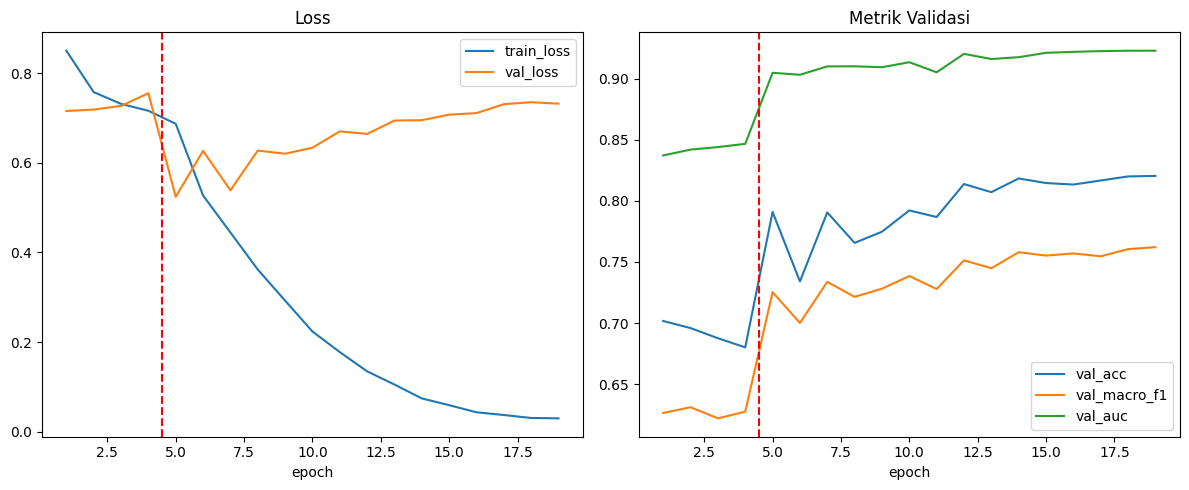

[INFO] Model terbaik dimuat dari /content/drive/MyDrive/riset_kanker_kulit/best_convnext_tiny_irisan_12W12P_r2.pt
=== CLASSIFICATION REPORT (VALIDATION SET - EXP 5-C) ===
                      precision    recall  f1-score   support

            melanoma       0.73      0.70      0.71       594
               nevus       0.87      0.92      0.89      1462
seborrheic_keratosis       0.74      0.63      0.68       354

            accuracy                           0.82      2410
           macro avg       0.78      0.75      0.76      2410
        weighted avg       0.82      0.82      0.82      2410

=== CLASSIFICATION REPORT (TEST SET - EXP 5-C) ===
                      precision    recall  f1-score   support

            melanoma       0.73      0.71      0.72       540
               nevus       0.89      0.91      0.90      1491
seborrheic_keratosis       0.75      0.73      0.74       312

            accuracy                           0.84      2343
           macro avg       0.

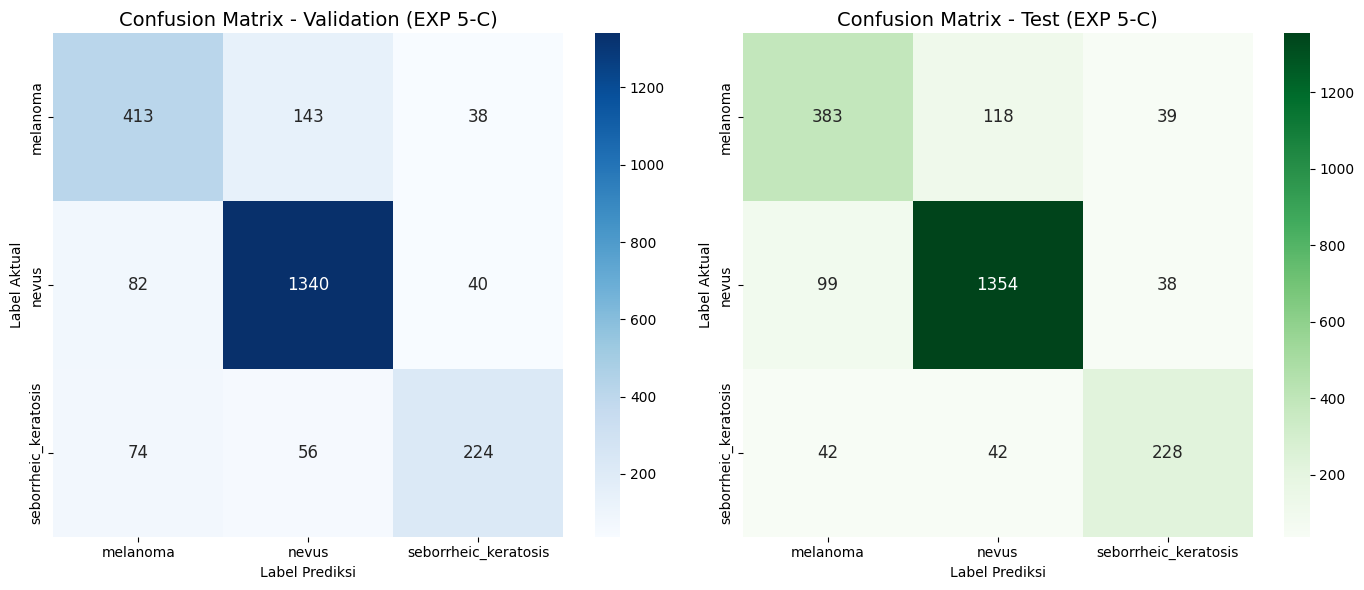

In [26]:
# ==========================================
# EVALUASI MODEL CONVNEXT-TINY (VALIDATION & BLIND TEST)
# ==========================================
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

hist = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
hist.plot(x="epoch", y=["train_loss", "val_loss"], ax=axes[0], title="Loss")
hist.plot(x="epoch", y=["val_acc", "val_macro_f1", "val_auc"], ax=axes[1], title="Metrik Validasi")
for ax in axes:
    ax.axvline(CFG["stage1_epochs"] + 0.5, ls="--", c="red")
plt.tight_layout()
plt.show()

model.load_state_dict(torch.load(best_model_path, map_location=dev))
print(f"[INFO] Model terbaik dimuat dari {best_model_path}")

P_val, P_test = predict(dl_val), predict(dl_test)
pred_val, pred_test = P_val.argmax(1), P_test.argmax(1)

print("=== CLASSIFICATION REPORT (VALIDATION SET - EXP 5-C) ===")
print(classification_report(y_val, pred_val, target_names=class_names))
print("=== CLASSIFICATION REPORT (TEST SET - EXP 5-C) ===")
print(classification_report(y_test, pred_test, target_names=class_names))

rep = classification_report(y_test, pred_test, target_names=class_names, output_dict=True)
acc_test = rep["accuracy"]
macro_f1 = rep["macro avg"]["f1-score"]
mel_recall = rep["melanoma"]["recall"]
sk_recall = rep["seborrheic_keratosis"]["recall"]
score = (acc_test + macro_f1 + mel_recall + sk_recall) / 4.0

print("=== SKOR SELEKSI INTERNAL EKSPERIMEN 5-C ===")
print(f"Val Loss     : {hist.loc[hist.val_macro_f1.idxmax(), 'val_loss']:.4f}")
print(f"Test AUC     : {roc_auc_score(y_test, P_test, multi_class='ovr', average='macro'):.4f}")
print(f"Accuracy     : {acc_test * 100:.2f}%")
print(f"Macro-F1     : {macro_f1:.4f}")
print(f"Mel Recall   : {mel_recall:.4f}")
print(f"SK Recall    : {sk_recall:.4f}")
print(f"Score Seleksi: {score:.4f}")
print("==========================================")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (title, yt, yp, cmap) in zip(axes, [("Validation", y_val, pred_val, "Blues"), ("Test", y_test, pred_test, "Greens")]):
    sns.heatmap(confusion_matrix(yt, yp), annot=True, fmt="d", cmap=cmap,
                xticklabels=class_names, yticklabels=class_names, annot_kws={"size": 12}, ax=ax)
    ax.set_title(f"Confusion Matrix - {title} (EXP 5-C)", fontsize=14)
    ax.set_ylabel("Label Aktual")
    ax.set_xlabel("Label Prediksi")
plt.tight_layout()
plt.show()

# Metrik tambahan untuk pencatatan results.csv
test_auc = roc_auc_score(y_test, P_test, multi_class='ovr', average='macro')
test_loss = float(-np.log(P_test[np.arange(len(y_test)), y_test] + 1e-12).mean())

In [27]:
from IPython.display import display

log_result(
    stage="training_centralized_gpu",
    elapsed_sec=training_time_sec,
    image_count=len(X_train),
    accuracy=acc_test,
    f1=macro_f1,
    loss=test_loss,
    roc_auc=test_auc,
    val_f1=best_val_f1,
)

print("\n=== ISI results.csv ===")
display(pd.read_csv(RESULTS_LOG_PATH))

[LOG] training_centralized_gpu (irisan_12W12P, replikasi 2) -> results.csv

=== ISI results.csv ===


,timestamp,scenario,num_workers,num_partitions,stage,elapsed_sec,image_count,avg_cpu_percent,avg_mem_mb,accuracy,f1_score,loss,roc_auc,replicate,val_macro_f1
0,2026-10-10 01:37:08,irisan_12W8P,12,8,yarn_container_allocation,0.02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN
1,2026-10-10 01:45:59,irisan_12W8P,12,8,preprocessing,505.20,24466.0,74.43,16670.03,NaN,NaN,NaN,NaN,1,NaN
2,2026-10-10 01:46:21,irisan_12W8P,12,8,shard_write,17.26,24466.0,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN
3,2026-10-10 01:46:38,irisan_12W8P,12,8,collect_driver,16.21,24466.0,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN
4,2026-10-10 01:58:48,irisan_12W8P,12,8,training_centralized_gpu,707.20,19713.0,NaN,NaN,0.8387,0.7867,0.5733,0.936,1,0.7621
5,2026-10-10 02:10:31,irisan_12W12P,12,12,yarn_container_allocation,0.02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,NaN
6,2026-10-10 02:18:14,irisan_12W12P,12,12,preprocessing,437.28,24466.0,98.30,17593.69,NaN,NaN,NaN,NaN,2,NaN
7,2026-10-10 02:18:34,irisan_12W12P,12,12,shard_write,15.38,24466.0,NaN,NaN,NaN,NaN,NaN,NaN,2,NaN
8,2026-10-10 02:18:53,irisan_12W12P,12,12,collect_driver,17.94,24466.0,NaN,NaN,NaN,NaN,NaN,NaN,2,NaN
9,2026-10-10 02:30:50,irisan_12W12P,12,12,training_centralized_gpu,706.06,19713.0,NaN,NaN,0.8387,0.7867,0.5733,0.936,2,0.7621


## Rekap dan Komparasi Skenario
Grafik dan tabel dibuat otomatis dari `results.csv`. Jika satu skenario dijalankan lebih dari sekali (replikasi), batang menunjukkan rata-rata ± simpangan baku dan titik menunjukkan tiap run.

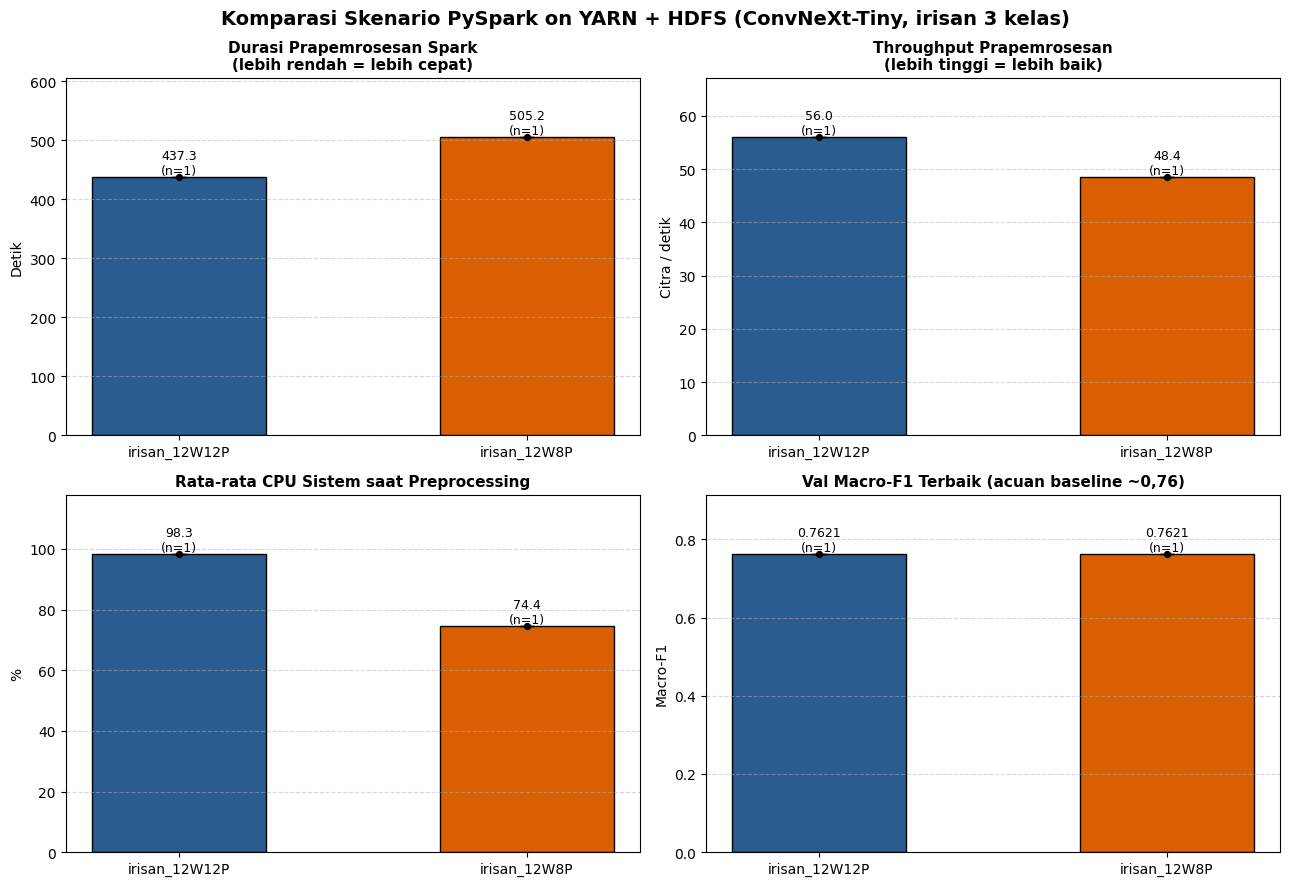

Grafik komparasi tersimpan di: /content/drive/MyDrive/riset_kanker_kulit/grafik_komparasi_skenario.png


In [28]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df = pd.read_csv(RESULTS_LOG_PATH)
for col in ["elapsed_sec", "avg_cpu_percent", "avg_mem_mb", "accuracy", "f1_score", "loss",
            "roc_auc", "val_macro_f1", "image_count"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df_prep = df[df["stage"] == "preprocessing"].copy()
df_prep["throughput"] = df_prep["image_count"] / df_prep["elapsed_sec"]
df_train = df[df["stage"] == "training_centralized_gpu"].copy()

scenarios = sorted(df["scenario"].unique(), key=lambda s: (-int(s.split("_")[1].split("W")[0]), s))
palette = ["#2b5c8f", "#d95f02", "#3b8b88", "#7570b3"]


def bar_with_runs(ax, data, value_col, title, ylabel, fmt="{:.1f}", scale=1.0):
    xs = np.arange(len(scenarios))
    for i, sc in enumerate(scenarios):
        vals = data.loc[data["scenario"] == sc, value_col].dropna().to_numpy() * scale
        if len(vals) == 0:
            continue
        mean, std = vals.mean(), (vals.std(ddof=1) if len(vals) > 1 else 0.0)
        ax.bar(xs[i], mean, yerr=std, capsize=5, color=palette[i % len(palette)], edgecolor="black", width=0.5)
        ax.scatter(np.full(len(vals), xs[i]), vals, color="black", s=18, zorder=3)
        ax.text(xs[i], mean + std, fmt.format(mean) + f"\n(n={len(vals)})", ha="center", va="bottom", fontsize=9)
    ax.set_xticks(xs)
    ax.set_xticklabels(scenarios)
    ax.set_title(title, fontsize=11, fontweight="semibold")
    ax.set_ylabel(ylabel)
    ax.margins(y=0.2)
    ax.grid(axis="y", linestyle="--", alpha=0.5)


fig, axes = plt.subplots(2, 2, figsize=(13, 9))
fig.suptitle("Komparasi Skenario PySpark on YARN + HDFS (ConvNeXt-Tiny, irisan 3 kelas)",
             fontsize=14, fontweight="bold")
bar_with_runs(axes[0, 0], df_prep, "elapsed_sec", "Durasi Prapemrosesan Spark\n(lebih rendah = lebih cepat)", "Detik")
bar_with_runs(axes[0, 1], df_prep, "throughput", "Throughput Prapemrosesan\n(lebih tinggi = lebih baik)", "Citra / detik")
bar_with_runs(axes[1, 0], df_prep, "avg_cpu_percent", "Rata-rata CPU Sistem saat Preprocessing", "%")
bar_with_runs(axes[1, 1], df_train, "val_macro_f1", "Val Macro-F1 Terbaik (acuan baseline ~0,76)", "Macro-F1", fmt="{:.4f}")
plt.tight_layout()
output_chart = PROJECT_DIR / "grafik_komparasi_skenario.png"
plt.savefig(output_chart, dpi=300, bbox_inches="tight")
plt.show()
print(f"Grafik komparasi tersimpan di: {output_chart}")

In [29]:
# Tabel rekap: rata-rata per skenario dan tahap (detik), serta metrik kualitas model vs acuan baseline
stage_order = ["yarn_container_allocation", "preprocessing", "shard_write", "collect_driver", "training_centralized_gpu"]
pivot = (df[df["stage"].isin(stage_order)]
         .pivot_table(index="stage", columns="scenario", values="elapsed_sec", aggfunc="mean")
         .reindex(stage_order))
print("=== Rata-rata waktu per tahap (detik) ===")
print(pivot.round(2).to_string())

quality = (df_train.groupby("scenario")[["val_macro_f1", "accuracy", "f1_score", "roc_auc", "loss"]]
           .agg(["mean", "std", "count"]))
print("\n=== Kualitas model (test: accuracy, f1_score = macro-F1, roc_auc, loss) ===")
print(quality.round(4).to_string())

BASELINE_REF = {"val_macro_f1": 0.7621, "accuracy": 0.8387, "f1_score": 0.7867, "roc_auc": 0.9360}
print("\n=== Acuan baseline ConvNeXt-Tiny (non-Spark, run tunggal) ===")
print(BASELINE_REF)

=== Rata-rata waktu per tahap (detik) ===
scenario                   irisan_12W12P  irisan_12W8P
stage                                                 
yarn_container_allocation           0.02          0.02
preprocessing                     437.28        505.20
shard_write                        15.38         17.26
collect_driver                     17.94         16.21
training_centralized_gpu          706.06        707.20

=== Kualitas model (test: accuracy, f1_score = macro-F1, roc_auc, loss) ===
              val_macro_f1           accuracy           f1_score           roc_auc              loss          
                      mean std count     mean std count     mean std count    mean std count    mean std count
scenario                                                                                                      
irisan_12W12P       0.7621 NaN     1   0.8387 NaN     1   0.7867 NaN     1   0.936 NaN     1  0.5733 NaN     1
irisan_12W8P        0.7621 NaN     1   0.8387 NaN   

In [30]:
# Metrik Spark lintas skenario/replikasi (dibaca dari spark_metrics_*.json di Drive)
rows_ = []
for p_ in sorted(PROJECT_DIR.glob("spark_metrics_*.json")):
    with open(p_) as f_:
        j = json.load(f_)
    sh = j["shuffle"]
    rows_.append({
        "skenario": j["scenario"], "ulangan": j["replicate"],
        "waktu_s": j["wall_sec"], "citra/dtk": j["throughput"]["total_ips"],
        "citra/dtk/core": j["throughput"]["per_core_ips"],
        "CPU_rata2_%": j["resource"]["avg_cpu"], "RAM_puncak_MB": j["resource"]["peak_mem_mb"],
        "CPU_worker_py_s": j["resource"]["python_cpu_sec"],
        "shuffle_write_KB": (sh.get("write_bytes", float("nan")) / 1024),
        "executor_dipakai": j["skew"]["executors_used"], "task_paralel_puncak": j["skew"]["peak_concurrent_tasks"],
        "gelombang_diharapkan": j["skew"]["waves_expected"],
        "paralelisme_efektif": j["skew"]["effective_parallelism"],
        "slot_util_%": j["skew"]["slot_utilization_pct"],
        "CV_citra/partisi_%": j["skew"]["images_per_partition"]["cv_pct"],
        "CV_durasi_task_%": j["skew"]["task_sec"]["cv_pct"],
        "straggler_s": j["skew"]["straggler_gap_sec"],
    })
if rows_:
    print("=== Metrik Spark per skenario dan ulangan ===")
    display(pd.DataFrame(rows_).round(2))
else:
    print("Belum ada berkas spark_metrics_*.json.")

=== Metrik Spark per skenario dan ulangan ===


,skenario,ulangan,waktu_s,citra/dtk,citra/dtk/core,CPU_rata2_%,RAM_puncak_MB,CPU_worker_py_s,shuffle_write_KB,executor_dipakai,task_paralel_puncak,gelombang_diharapkan,paralelisme_efektif,slot_util_%,CV_citra/partisi_%,CV_durasi_task_%,straggler_s
0,irisan_12W12P,2,437.28,55.95,4.66,98.30,21164.59,4753.14,499.51,12,12,1,11.62,96.85,0.38,1.24,6.78
1,irisan_12W8P,1,505.20,48.43,4.04,74.43,19718.05,3962.47,499.34,8,8,1,7.77,64.73,0.31,1.28,11.10
